In [1]:
import sys
import importlib

print("Python executable:", sys.executable)

packages = [
    "numpy", "pandas", "scipy", "statsmodels",
    "matplotlib", "pytest", "jupyter", "notebook",
    "ipykernel", "nbformat", "nbclient",
    "nbconvert", "jsonschema"
]

for package in packages:
    importlib.import_module(package)
    print(f"{package}: OK")

Python executable: C:\Users\msi1\AppData\Local\Programs\Python\Python310\python.exe
numpy: OK
pandas: OK
scipy: OK
statsmodels: OK
matplotlib: OK
pytest: OK
jupyter: OK
notebook: OK
ipykernel: OK
nbformat: OK
nbclient: OK
nbconvert: OK
jsonschema: OK


# Step 2: Sample Size Planning

## Objective
Calculate the minimum number of users required in each group to detect a meaningful difference in conversion rates.

## Experiment Planning Assumptions
- Control conversion rate: 5.0%
- Treatment planning conversion rate: 5.5%
- Minimum Detectable Effect (MDE): 0.5 percentage points
- Significance level (alpha): 0.05
- Target statistical power: 80%
- Allocation ratio: 1:1

We will use statsmodels to calculate the required sample size before analysing experimental results.

In [2]:
from math import ceil

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Define experiment planning assumptions
control_rate = 0.05
treatment_planning_rate = 0.055
alpha = 0.05
target_power = 0.80
planned_users_per_group = 35_000

# Calculate Cohen's h effect size for two proportions
effect_size = abs(
    proportion_effectsize(control_rate, treatment_planning_rate)
)

# Calculate the minimum required sample size
power_analysis = NormalIndPower()

required_users_raw = power_analysis.solve_power(
    effect_size=effect_size,
    power=target_power,
    alpha=alpha,
    ratio=1.0,
    alternative="two-sided"
)

# Round upward because users must be whole numbers
required_users_per_group = ceil(required_users_raw)

# Calculate the power of our planned sample size
achieved_power = power_analysis.power(
    effect_size=effect_size,
    nobs1=planned_users_per_group,
    alpha=alpha,
    ratio=1.0,
    alternative="two-sided"
)

# Display the results
print(f"Cohen's h effect size: {effect_size:.5f}")
print(f"Required users per group: {required_users_per_group:,}")
print(f"Required total users: {2 * required_users_per_group:,}")
print(f"Planned users per group: {planned_users_per_group:,}")
print(f"Planned total users: {2 * planned_users_per_group:,}")
print(f"Achieved nominal power: {achieved_power:.2%}")

Cohen's h effect size: 0.02242
Required users per group: 31,218
Required total users: 62,436
Planned users per group: 35,000
Planned total users: 70,000
Achieved nominal power: 84.29%


### Sample Size Planning — Observation

The sample-size calculation requires 31,218 users per group,
or 62,436 users in total, to achieve the target statistical power
of 80% for detecting an absolute conversion difference of
0.5 percentage points (5.0% versus 5.5%), at a two-sided
significance level of 5%.

Our planned sample of 70,000 users (35,000 per group) exceeds
this requirement. The estimated nominal statistical power is
84.29%.

These calculations depend on the planning assumptions.
They do not guarantee a statistically significant result,
and statistical power is not the probability that the
treatment will succeed.

### Understanding Cohen's h

Cohen's h is a standardized measure of the difference between two proportions.

In our project, the planning conversion rates are 5.0% for Control and 5.5% for Treatment. Their absolute difference is 0.5 percentage points, corresponding to Cohen's h of approximately 0.02242.

We use Cohen's h as an input for sample-size and statistical-power calculations. It is not the conversion lift itself.

## Calibration: Reference Population

We create a reference population of 1,000,000 synthetic customer profiles
to calibrate the purchase-probability model.

We generate cart values, customer types, device types, and traffic sources
using the locked random seed.

Both discount policies are evaluated on the same reference population.
This ensures that their eligibility rates are compared fairly.

This reference population is used for calibration, not as the final
70,000-user experiment dataset.

In [3]:
import numpy as np

# Locked calibration settings
REFERENCE_SIZE = 1_000_000
CALIBRATION_SEED = 2025

CART_MEDIAN = 1800
CART_LOG_SIGMA = 0.45

# Create a reproducible random number generator
rng = np.random.Generator(np.random.PCG64(CALIBRATION_SEED))

# Generate customer characteristics in the locked order

# 1. Cart value: lognormal distribution
cart_value = rng.lognormal(
    mean=np.log(CART_MEDIAN),
    sigma=CART_LOG_SIGMA,
    size=REFERENCE_SIZE
)

# 2. Customer type
is_returning = rng.random(REFERENCE_SIZE) < 0.35

# 3. Device type
device_type = rng.choice(
    ["mobile", "desktop", "tablet"],
    size=REFERENCE_SIZE,
    p=[0.65, 0.28, 0.07]
)

# 4. Traffic source
traffic_source = rng.choice(
    ["paid", "organic", "email"],
    size=REFERENCE_SIZE,
    p=[0.50, 0.35, 0.15]
)

# Calculate potential eligibility under both policies
eligible_under_control = cart_value >= 999
eligible_under_treatment = cart_value >= 1499

# Display the actual results
print(f"Reference population: {REFERENCE_SIZE:,}")

print(
    "Control eligibility rate:",
    f"{eligible_under_control.mean():.4%}"
)

print(
    "Treatment eligibility rate:",
    f"{eligible_under_treatment.mean():.4%}"
)

print(f"Returning customer share: {is_returning.mean():.2%}")
print(f"Mobile share: {(device_type == 'mobile').mean():.2%}")
print(f"Paid traffic share: {(traffic_source == 'paid').mean():.2%}")

Reference population: 1,000,000
Control eligibility rate: 90.4429%
Treatment eligibility rate: 65.7470%
Returning customer share: 35.01%
Mobile share: 64.96%
Paid traffic share: 50.08%


### Calibration Reference Population — Observation

The reference population contains 1,000,000 simulated users.

Control eligibility is 90.4429%, while Treatment eligibility is
65.7470%. Treatment has a higher minimum basket threshold of ₹1,499,
compared with ₹999 for Control, so fewer users qualify for Treatment.

The returning-customer, mobile-device, and paid-traffic proportions
are close to their configured targets.

Eligibility is not the same as purchase conversion or offer application.
These results describe a simulated reference population, not real customers.

## Purchase Probability Model

We now prepare a logistic probability model using customer characteristics.

The model considers:
- Cart value
- Customer type
- Device type
- Traffic source

Each characteristic contributes to a base score through its predefined coefficient.

This score will later be combined with the assigned discount policy
to calculate each customer's purchase probability.

These coefficients are synthetic simulation assumptions.

In [4]:
# Define locked simulation coefficients

BETA_LOG_CART = 0.25
BETA_RETURNING = 0.25
BETA_PAID = -0.10
BETA_EMAIL = 0.10
BETA_MOBILE = -0.10
BETA_TABLET = 0.00

BASE_DISCOUNT_SENSITIVITY = 0.25

# Convert categorical characteristics into numerical indicators

is_paid = (traffic_source == "paid").astype(float)
is_email = (traffic_source == "email").astype(float)

is_mobile = (device_type == "mobile").astype(float)
is_tablet = (device_type == "tablet").astype(float)

is_returning_numeric = is_returning.astype(float)

# Calculate the contribution of customer characteristics

base_score = (
    BETA_LOG_CART * np.log(cart_value / CART_MEDIAN)
    + BETA_RETURNING * is_returning_numeric
    + BETA_PAID * is_paid
    + BETA_EMAIL * is_email
    + BETA_MOBILE * is_mobile
    + BETA_TABLET * is_tablet
)

# Display basic diagnostics

print("Base score calculation completed.")

print(f"Mean base score: {base_score.mean():.5f}")
print(f"Minimum base score: {base_score.min():.5f}")
print(f"Maximum base score: {base_score.max():.5f}")
print(f"Total reference users: {len(base_score):,}")

Base score calculation completed.
Mean base score: -0.01257
Minimum base score: -0.69771
Maximum base score: 0.85618
Total reference users: 1,000,000


## Logistic Function (Sigmoid)

The logistic function converts a numerical model score into a probability between 0 and 1.

We will use this function later to calculate the purchase probability of each simulated customer.

In [5]:
import numpy as np
from scipy.special import expit

# Convert model scores into probabilities
sample_scores = np.array([-2.0, 0.0, 2.0])

sample_probabilities = expit(sample_scores)

for score, probability in zip(sample_scores, sample_probabilities):
    print(f"Score: {score: .1f} | Probability: {probability:.2%}")

# Verify that all probabilities are between 0 and 1
assert np.all(sample_probabilities >= 0)
assert np.all(sample_probabilities <= 1)

print("\nValidation passed!")

Score: -2.0 | Probability: 11.92%
Score:  0.0 | Probability: 50.00%
Score:  2.0 | Probability: 88.08%

Validation passed!


In [6]:
import numpy as np
from scipy.special import expit

# Convert model scores into probabilities
sample_scores = np.array([-2.0, 0.0, 2.0])

sample_probabilities = expit(sample_scores)

for score, probability in zip(sample_scores, sample_probabilities):
    print(f"Score: {score: .1f} | Probability: {probability:.2%}")

# Verify that all probabilities are between 0 and 1
assert np.all(sample_probabilities >= 0)
assert np.all(sample_probabilities <= 1)

print("\nValidation passed!")

Score: -2.0 | Probability: 11.92%
Score:  0.0 | Probability: 50.00%
Score:  2.0 | Probability: 88.08%

Validation passed!


## Calibration of Purchase Probabilities

We use scipy.optimize.least_squares to estimate two parameters:

1. Intercept
2. Incremental treatment discount sensitivity

The calibration process adjusts these parameters until the average
predicted purchase probabilities match our predefined targets:

- Control: 5%
- Treatment: 6%

Both policies are evaluated on the same reference population.

These are simulated probability targets, not actual observed conversion rates.

In [7]:
from scipy.optimize import least_squares
from scipy.special import expit

# Define target purchase probabilities
TARGET_CONTROL = 0.05
TARGET_TREATMENT = 0.06


# Calculate the difference between predicted and target probabilities
def calibration_residuals(parameters):

    intercept, incremental_sensitivity = parameters

    # Control purchase probability
    eta_control = (
        intercept
        + base_score
        + BASE_DISCOUNT_SENSITIVITY * eligible_under_control
    )

    # Treatment purchase probability
    eta_treatment = (
        intercept
        + base_score
        + (BASE_DISCOUNT_SENSITIVITY + incremental_sensitivity)
        * eligible_under_treatment
    )

    predicted_control = expit(eta_control).mean()
    predicted_treatment = expit(eta_treatment).mean()

    return np.array([
        predicted_control - TARGET_CONTROL,
        predicted_treatment - TARGET_TREATMENT
    ])


# Find the parameters that best match our targets
calibration_result = least_squares(
    calibration_residuals,
    x0=[-4.0, 0.5],
    bounds=([-10.0, 0.0], [0.0, 1.0]),
    max_nfev=10000
)

# Extract calibrated parameters
calibrated_intercept, calibrated_sensitivity = calibration_result.x

# Calculate final calibrated probabilities
final_residuals = calibration_residuals(calibration_result.x)

calibrated_control = TARGET_CONTROL + final_residuals[0]
calibrated_treatment = TARGET_TREATMENT + final_residuals[1]

# Display results
print("Calibration successful:", calibration_result.success)

print(f"Calibrated intercept: {calibrated_intercept:.6f}")
print(f"Incremental sensitivity: {calibrated_sensitivity:.6f}")

print(f"Control target: {TARGET_CONTROL:.2%}")
print(f"Control calibrated: {calibrated_control:.6%}")

print(f"Treatment target: {TARGET_TREATMENT:.2%}")
print(f"Treatment calibrated: {calibrated_treatment:.6%}")

print(f"Maximum calibration error: {np.max(np.abs(final_residuals)):.10f}")

# Strict validation
assert calibration_result.success
assert calibrated_sensitivity >= 0 and calibrated_sensitivity <= 1
assert np.max(np.abs(final_residuals)) <= 1e-6

print("\nCalibration validation passed!")

Calibration successful: True
Calibrated intercept: -3.179635
Incremental sensitivity: 0.322060
Control target: 5.00%
Control calibrated: 5.000000%
Treatment target: 6.00%
Treatment calibrated: 6.000000%
Maximum calibration error: 0.0000000000

Calibration validation passed!


### Calibration Results — Observation

The calibration process successfully estimated the intercept
at -3.179635 and incremental treatment sensitivity at 0.322060.

The average predicted purchase probabilities match the
predefined targets exactly:

- Control: 5.00%
- Treatment: 6.00%

The maximum calibration error is zero.

This confirms that the simulation model matches its predefined
probability targets. Actual purchase outcomes may differ because
they will be generated probabilistically.

## Individual Purchase Probabilities

We now calculate an individual purchase probability for every
customer under both discount policies.

Both policies use the same customer characteristics, allowing
a fair comparison of their predicted purchase probabilities.

The average probabilities should match the calibration targets:
- Control: 5%
- Treatment: 6%

No actual purchase outcomes are generated in this step.

In [8]:
# Calculate Control model scores
eta_control = (
    calibrated_intercept
    + base_score
    + BASE_DISCOUNT_SENSITIVITY * eligible_under_control
)

# Calculate Treatment model scores
eta_treatment = (
    calibrated_intercept
    + base_score
    + (BASE_DISCOUNT_SENSITIVITY + calibrated_sensitivity)
    * eligible_under_treatment
)

# Convert scores into individual purchase probabilities
probability_control = expit(eta_control)
probability_treatment = expit(eta_treatment)

# Display average probabilities
print("Control average probability:",
      f"{probability_control.mean():.4%}")

print("Treatment average probability:",
      f"{probability_treatment.mean():.4%}")

# Check probability ranges
print("\nControl probability range:",
      f"{probability_control.min():.4%} - {probability_control.max():.4%}")

print("Treatment probability range:",
      f"{probability_treatment.min():.4%} - {probability_treatment.max():.4%}")

# Validation
assert np.all((probability_control >= 0) & (probability_control <= 1))
assert np.all((probability_treatment >= 0) & (probability_treatment <= 1))

assert abs(probability_control.mean() - 0.05) <= 1e-6
assert abs(probability_treatment.mean() - 0.06) <= 1e-6

print("\nProbability validation passed!")

Control average probability: 5.0000%
Treatment average probability: 6.0000%

Control probability range: 2.0286% - 11.1704%
Treatment probability range: 2.0286% - 14.7871%

Probability validation passed!


### Individual Purchase Probability — Observation

The calibrated model generated individual purchase probabilities
for all 1,000,000 reference customers under both policies.

The average predicted probability is 5.00% for Control
and 6.00% for Treatment.

Individual probabilities vary according to customer characteristics
and offer eligibility.

These are predicted probabilities, not actual purchase outcomes.
Actual purchases will be simulated separately using Bernoulli trials.

## Bernoulli Trial — Simulating Purchase Outcomes

A Bernoulli trial generates a binary outcome based on an individual
purchase probability.

- 1 represents a purchase.
- 0 represents no purchase.

We use this method to simulate customer purchase decisions.
This is an educational demonstration, not our final experiment dataset.

In [9]:
# Take the first 10 customers from our reference population
demo_probabilities = probability_control[:10]

# Use a separate random generator for this demonstration
demo_rng = np.random.default_rng(42)

# Generate binary purchase outcomes
demo_purchases = demo_rng.binomial(
    n=1,
    p=demo_probabilities
)

# Display results
for i, (probability, purchase) in enumerate(
    zip(demo_probabilities, demo_purchases),
    start=1
):
    print(
        f"Customer {i}: "
        f"Probability = {probability:.2%}, "
        f"Purchase = {purchase}"
    )

print("\nTotal purchases:", demo_purchases.sum())
print("Total customers:", len(demo_purchases))

Customer 1: Probability = 3.99%, Purchase = 0
Customer 2: Probability = 5.33%, Purchase = 0
Customer 3: Probability = 6.06%, Purchase = 0
Customer 4: Probability = 4.08%, Purchase = 0
Customer 5: Probability = 2.78%, Purchase = 0
Customer 6: Probability = 5.00%, Purchase = 1
Customer 7: Probability = 4.90%, Purchase = 0
Customer 8: Probability = 4.31%, Purchase = 0
Customer 9: Probability = 4.52%, Purchase = 0
Customer 10: Probability = 6.03%, Purchase = 0

Total purchases: 1
Total customers: 10


### Bernoulli Trial — Observation

The simulation generated binary purchase outcomes for 10 customers.

One customer purchased (1), while nine customers did not purchase (0).

Each outcome was generated using the customer's individual purchase
probability. Actual purchases can differ from expected purchases
because of random variation.

This is a small demonstration, not the final experiment dataset.

## Final Experiment Population — 70,000 Users

We create the final synthetic experiment population of 70,000 unique users.

Each user receives:
- A simulated cart value
- A customer type
- A device type
- A traffic source
- An assignment timestamp
- A randomly assigned experiment variant

Users are randomly assigned in a 50:50 ratio:
- Control A: 35,000 users
- Treatment B: 35,000 users

We also calculate eligibility under both discount policies.

Purchase outcomes have not been generated at this stage.

In [11]:
import pandas as pd

# Locked experiment settings
DATA_SEED = 2026
TOTAL_USERS = 70_000
USERS_PER_GROUP = TOTAL_USERS // 2

# Separate random generator for final experiment data
data_rng = np.random.Generator(np.random.PCG64(DATA_SEED))

# 1. Generate cart values
final_cart_values = np.round(
    data_rng.lognormal(
        mean=np.log(1800),
        sigma=0.45,
        size=TOTAL_USERS
    ),
    2
)

# 2. Generate customer types
final_is_returning = data_rng.random(TOTAL_USERS) < 0.35

final_customer_type = np.where(
    final_is_returning,
    "returning",
    "new"
)

# 3. Generate device types
final_device_type = data_rng.choice(
    ["mobile", "desktop", "tablet"],
    size=TOTAL_USERS,
    p=[0.65, 0.28, 0.07]
)

# 4. Generate traffic sources
final_traffic_source = data_rng.choice(
    ["paid", "organic", "email"],
    size=TOTAL_USERS,
    p=[0.50, 0.35, 0.15]
)

# 5. Generate assignment timestamps
day_offsets = data_rng.integers(0, 28, size=TOTAL_USERS)
second_offsets = data_rng.integers(0, 86400, size=TOTAL_USERS)

assigned_at = (
    pd.Timestamp("2026-01-01")
    + pd.to_timedelta(day_offsets, unit="D")
    + pd.to_timedelta(second_offsets, unit="s")
)

# 6. Create an exact 50:50 allocation
variant = np.array(
    ["Control"] * USERS_PER_GROUP
    + ["Treatment"] * USERS_PER_GROUP
)

# Randomly shuffle group assignments
data_rng.shuffle(variant)

# 7. Calculate eligibility under both policies
eligible_control = final_cart_values >= 999
eligible_treatment = final_cart_values >= 1499

# Select eligibility based on assigned variant
eligible_for_offer = np.where(
    variant == "Control",
    eligible_control,
    eligible_treatment
)

# 8. Create the experiment population DataFrame
experiment_df = pd.DataFrame({
    "user_id": [f"U{i:06d}" for i in range(1, TOTAL_USERS + 1)],
    "experiment_id": "discount_offer_2026",
    "assigned_at": assigned_at,
    "variant": variant,
    "cart_value": final_cart_values,
    "customer_type": final_customer_type,
    "device_type": final_device_type,
    "traffic_source": final_traffic_source,
    "eligible_under_control": eligible_control,
    "eligible_under_treatment": eligible_treatment,
    "eligible_for_offer": eligible_for_offer
})

# 9. Display basic validation results
print("Dataset shape:", experiment_df.shape)

print("\nUsers by variant:")
print(experiment_df["variant"].value_counts().sort_index())

print("\nUnique user IDs:", experiment_df["user_id"].nunique())

print("\nEligibility rate by variant:")
print(
    experiment_df.groupby("variant")["eligible_for_offer"]
    .mean()
    .map(lambda x: f"{x:.2%}")
)

# 10. Basic assertions
assert len(experiment_df) == 70_000
assert experiment_df["user_id"].is_unique
assert experiment_df["variant"].value_counts()["Control"] == 35_000
assert experiment_df["variant"].value_counts()["Treatment"] == 35_000

print("\nExperiment population validation passed!")

Dataset shape: (70000, 11)

Users by variant:
variant
Control      35000
Treatment    35000
Name: count, dtype: int64

Unique user IDs: 70000

Eligibility rate by variant:
variant
Control      90.58%
Treatment    65.72%
Name: eligible_for_offer, dtype: object

Experiment population validation passed!


### Final Experiment Population — Observation

The final synthetic experiment population contains 70,000 unique users,
randomly assigned equally between Control and Treatment.

Each group contains exactly 35,000 users.

Control eligibility is 90.58%, while Treatment eligibility is 65.72%.
The lower Treatment eligibility is explained by its higher minimum
basket threshold of ₹1,499.

The user assignment and eligibility validation checks passed.

Purchase outcomes have not yet been generated.

## Purchase Probabilities for the Final Experiment Population

We apply the calibrated logistic model to all 70,000 experiment users.

Each user receives two potential probability estimates:
- Purchase probability under Control policy.
- Purchase probability under Treatment policy.

The probability corresponding to the user's randomly assigned
variant will be selected for the experiment.

These are predicted probabilities, not actual purchase outcomes.

# Extract customer characteristics from the final experiment dataset

final_is_returning = (
    experiment_df["customer_type"] == "returning"
).to_numpy(dtype=float)

final_is_paid = (
    experiment_df["traffic_source"] == "paid"
).to_numpy(dtype=float)

final_is_email = (
    experiment_df["traffic_source"] == "email"
).to_numpy(dtype=float)

final_is_mobile = (
    experiment_df["device_type"] == "mobile"
).to_numpy(dtype=float)

final_is_tablet = (
    experiment_df["device_type"] == "tablet"
).to_numpy(dtype=float)

# Calculate the base score for all 70,000 users

final_base_score = (
    BETA_LOG_CART
    * np.log(experiment_df["cart_value"].to_numpy() / CART_MEDIAN)
    + BETA_RETURNING * final_is_returning
    + BETA_PAID * final_is_paid
    + BETA_EMAIL * final_is_email
    + BETA_MOBILE * final_is_mobile
    + BETA_TABLET * final_is_tablet
)

# Calculate potential Control and Treatment probabilities

final_eta_control = (
    calibrated_intercept
    + final_base_score
    + BASE_DISCOUNT_SENSITIVITY
    * experiment_df["eligible_under_control"].to_numpy()
)

final_eta_treatment = (
    calibrated_intercept
    + final_base_score
    + (BASE_DISCOUNT_SENSITIVITY + calibrated_sensitivity)
    * experiment_df["eligible_under_treatment"].to_numpy()
)

final_probability_control = expit(final_eta_control)
final_probability_treatment = expit(final_eta_treatment)

# Select probability according to the user's assigned variant

experiment_df["purchase_probability_control"] = final_probability_control
experiment_df["purchase_probability_treatment"] = final_probability_treatment

experiment_df["purchase_probability"] = np.where(
    experiment_df["variant"] == "Control",
    experiment_df["purchase_probability_control"],
    experiment_df["purchase_probability_treatment"]
)

# Display actual results

print("Total experiment users:", len(experiment_df))

print("\nAverage predicted probability by assigned group:")
print(
    experiment_df.groupby("variant")["purchase_probability"]
    .mean()
    .map(lambda x: f"{x:.4%}")
)

print("\nOverall probability range:")
print(
    f"{experiment_df['purchase_probability'].min():.4%}"
    f" - "
    f"{experiment_df['purchase_probability'].max():.4%}"
)

# Validation
assert len(experiment_df) == 70_000
assert experiment_df["purchase_probability"].between(0, 1).all()
assert experiment_df["purchase_probability"].notna().all()

print("\nFinal probability validation passed!")

### Final Experiment Purchase Probabilities — Observation

The calibrated logistic model was applied to all 70,000 experiment users.

The average predicted purchase probability is 5.0067% for Control
and 5.9960% for Treatment.

Both values are close to the predefined calibration targets
of 5% and 6%, respectively.

Individual purchase probabilities vary according to customer
characteristics and offer eligibility.

These are predicted probabilities, not observed purchase outcomes.

## Simulating Actual Purchase Outcomes

We now generate a binary purchase outcome for every randomized user.

Each user's individual purchase probability determines the likelihood
of purchasing.

We use a Bernoulli trial with the locked data-generation random seed.

The resulting purchase outcomes are simulated, not real transactions.

In [14]:
# Generate one Bernoulli purchase outcome per randomized user
# Use the existing data_rng to preserve the locked random-number sequence.

experiment_df["purchase_flag"] = data_rng.binomial(
    n=1,
    p=experiment_df["purchase_probability"].to_numpy()
)

# Count purchase outcomes by experiment group
purchase_summary = (
    experiment_df.groupby("variant")["purchase_flag"]
    .agg(
        total_users="count",
        purchasers="sum"
    )
)

purchase_summary["non_purchasers"] = (
    purchase_summary["total_users"]
    - purchase_summary["purchasers"]
)

print("Purchase outcome summary:")
print(purchase_summary)

# Validate generated outcomes
assert experiment_df["purchase_flag"].isin([0, 1]).all()
assert experiment_df["purchase_flag"].notna().all()
assert len(experiment_df) == 70_000

print("\nPurchase outcome validation passed!")

Purchase outcome summary:
           total_users  purchasers  non_purchasers
variant                                           
Control          35000        1787           33213
Treatment        35000        2111           32889

Purchase outcome validation passed!


### Simulated Purchase Outcomes — Observation

The simulation generated purchase outcomes for all 70,000 randomized users.

Control recorded 1,787 purchases out of 35,000 users,
resulting in an observed conversion rate of 5.1057%.

Treatment recorded 2,111 purchases out of 35,000 users,
resulting in an observed conversion rate of 6.0314%.

The observed absolute conversion difference is approximately
0.9257 percentage points in favour of Treatment.

This is a descriptive comparison only. Statistical significance
will be evaluated later using a two-proportion z-test and
confidence intervals.

All purchase outcomes are synthetic.

## Offer Application and Discount Calculation

We now determine whether each purchaser actually receives the assigned offer.

Business rules:
- Control: 10% discount for eligible purchasers.
- Treatment: 15% discount for eligible purchasers.
- Non-purchasers receive no discount.
- Purchasers below the minimum basket threshold receive no discount.

We calculate the pre-discount order value, discount amount,
and net checkout order value.

All monetary values are simulated and expressed in INR.

In [16]:
# Assign the discount rate according to the randomized variant

experiment_df["offer_discount_rate"] = np.where(
    experiment_df["variant"] == "Control",
    0.10,
    0.15
)

# An offer is applied only when the user purchases and is eligible
experiment_df["offer_applied"] = (
    (experiment_df["purchase_flag"] == 1)
    & experiment_df["eligible_for_offer"]
).astype(int)

# Record pre-discount order value for purchasers only
experiment_df["pre_discount_order_value"] = np.where(
    experiment_df["purchase_flag"] == 1,
    experiment_df["cart_value"],
    0.0
)

# Calculate discount only for users who actually receive the offer
experiment_df["discount_amount"] = np.where(
    experiment_df["offer_applied"] == 1,
    experiment_df["pre_discount_order_value"]
    * experiment_df["offer_discount_rate"],
    0.0
)

# Round monetary values to two decimal places
experiment_df["discount_amount"] = (
    experiment_df["discount_amount"].round(2)
)

# Calculate the final checkout value
experiment_df["net_checkout_order_value"] = (
    experiment_df["pre_discount_order_value"]
    - experiment_df["discount_amount"]
).round(2)

# Summarize results by experiment group
offer_summary = experiment_df.groupby("variant").agg(
    total_users=("user_id", "count"),
    eligible_users=("eligible_for_offer", "sum"),
    purchasers=("purchase_flag", "sum"),
    offers_applied=("offer_applied", "sum"),
    total_discount=("discount_amount", "sum")
)

offer_summary["eligibility_rate"] = (
    offer_summary["eligible_users"] / offer_summary["total_users"]
)

offer_summary["application_rate"] = (
    offer_summary["offers_applied"] / offer_summary["eligible_users"]
)

print("Offer application summary:")
print(offer_summary)

# Validation
assert (
    experiment_df["offer_applied"]
    <= experiment_df["purchase_flag"]
).all()

assert (
    experiment_df["offer_applied"]
    <= experiment_df["eligible_for_offer"].astype(int)
).all()

assert (
    experiment_df.loc[
        experiment_df["purchase_flag"] == 0,
        "discount_amount"
    ] == 0
).all()

assert (
    experiment_df["net_checkout_order_value"] >= 0
).all()

print("\nOffer application validation passed!")

Offer application summary:
           total_users  eligible_users  purchasers  offers_applied  \
variant                                                              
Control          35000           31703        1787            1678   
Treatment        35000           23002        2111            1688   

           total_discount  eligibility_rate  application_rate  
variant                                                        
Control         365977.28            0.9058          0.052929  
Treatment       629884.63            0.6572          0.073385  

Offer application validation passed!


### Offer Application — Business Observation

Control had 31,703 eligible users, while Treatment had 23,002.

A total of 1,678 Control purchasers and 1,688 Treatment purchasers
actually received their assigned discounts.

The offer application rate was 5.29% for Control and 7.34% for Treatment,
using eligible randomized users as the denominator.

Treatment generated a higher total discount cost of ₹629,884.63,
compared with ₹365,977.28 for Control.

These results are simulated. Higher offer application and discount
spending do not automatically imply higher profitability.

## Refund Simulation and Financial Calculations

We simulate refunds for purchasers using an 8% refund probability.

We then calculate:
- Retained revenue
- Retained COGS
- Fulfillment cost
- Payment processing fee
- Reverse logistics cost
- Contribution profit

Refunded orders have zero retained revenue and zero retained COGS.
However, fulfillment and payment processing costs remain incurred,
and reverse logistics cost is added.

All assumptions are illustrative and synthetic.

In [17]:
# Define locked economic assumptions

REFUND_PROBABILITY = 0.08
COGS_RATE = 0.60
FULFILLMENT_COST = 60.0
PAYMENT_FEE_RATE = 0.02
REVERSE_LOGISTICS_COST = 80.0

# Step 1: Generate refunds only for purchasers

experiment_df["refund_flag"] = 0

purchaser_indices = experiment_df.index[
    experiment_df["purchase_flag"] == 1
]

refund_outcomes = data_rng.binomial(
    n=1,
    p=REFUND_PROBABILITY,
    size=len(purchaser_indices)
)

experiment_df.loc[purchaser_indices, "refund_flag"] = refund_outcomes


# Step 2: Calculate estimated COGS

experiment_df["estimated_cogs"] = (
    experiment_df["pre_discount_order_value"] * COGS_RATE
).round(2)


# Step 3: Calculate retained revenue

experiment_df["retained_revenue"] = np.where(
    experiment_df["refund_flag"] == 1,
    0.0,
    experiment_df["net_checkout_order_value"]
)


# Step 4: Calculate retained COGS

experiment_df["retained_cogs"] = np.where(
    experiment_df["refund_flag"] == 1,
    0.0,
    experiment_df["estimated_cogs"]
)


# Step 5: Calculate fulfillment costs

experiment_df["fulfillment_cost"] = np.where(
    experiment_df["purchase_flag"] == 1,
    FULFILLMENT_COST,
    0.0
)


# Step 6: Calculate payment processing fees

experiment_df["payment_processing_fee"] = (
    experiment_df["net_checkout_order_value"]
    * PAYMENT_FEE_RATE
).round(2)


# Step 7: Calculate reverse logistics costs

experiment_df["reverse_logistics_cost"] = np.where(
    experiment_df["refund_flag"] == 1,
    REVERSE_LOGISTICS_COST,
    0.0
)


# Step 8: Calculate contribution profit

experiment_df["contribution_profit"] = (
    experiment_df["retained_revenue"]
    - experiment_df["retained_cogs"]
    - experiment_df["fulfillment_cost"]
    - experiment_df["payment_processing_fee"]
    - experiment_df["reverse_logistics_cost"]
).round(2)


# Step 9: Summarize financial results by group

financial_summary = experiment_df.groupby("variant").agg(
    total_users=("user_id", "count"),
    purchasers=("purchase_flag", "sum"),
    refunds=("refund_flag", "sum"),
    retained_revenue=("retained_revenue", "sum"),
    retained_cogs=("retained_cogs", "sum"),
    fulfillment_cost=("fulfillment_cost", "sum"),
    payment_fee=("payment_processing_fee", "sum"),
    reverse_logistics=("reverse_logistics_cost", "sum"),
    contribution_profit=("contribution_profit", "sum")
)

financial_summary["refund_rate"] = (
    financial_summary["refunds"] / financial_summary["purchasers"]
)

print("Financial summary by variant:")
print(financial_summary.round(2))


# Step 10: Validate financial rules

assert (
    experiment_df["refund_flag"] <= experiment_df["purchase_flag"]
).all()

non_purchasers = experiment_df["purchase_flag"] == 0

money_columns = [
    "estimated_cogs",
    "retained_revenue",
    "retained_cogs",
    "fulfillment_cost",
    "payment_processing_fee",
    "reverse_logistics_cost",
    "contribution_profit"
]

assert (
    experiment_df.loc[non_purchasers, money_columns] == 0
).all().all()

refunded = experiment_df["refund_flag"] == 1

assert (
    experiment_df.loc[refunded, "retained_revenue"] == 0
).all()

assert (
    experiment_df.loc[refunded, "retained_cogs"] == 0
).all()

assert (
    experiment_df.loc[refunded, "reverse_logistics_cost"]
    == REVERSE_LOGISTICS_COST
).all()

print("\nFinancial accounting validation passed!")

Financial summary by variant:
           total_users  purchasers  refunds  retained_revenue  retained_cogs  \
variant                                                                        
Control          35000        1787      147        3106633.69     2065688.54   
Treatment        35000        2111      168        3717279.32     2575929.43   

           fulfillment_cost  payment_fee  reverse_logistics  \
variant                                                       
Control            107220.0     67689.60            11760.0   
Treatment          126660.0     81085.55            13440.0   

           contribution_profit  refund_rate  
variant                                      
Control              854275.55         0.08  
Treatment            920164.34         0.08  

Financial accounting validation passed!


### Financial Analysis — Business Observation

Treatment generated ₹37.17 lakh in retained revenue,
compared with ₹31.07 lakh for Control.

Contribution profit was ₹9.20 lakh for Treatment
and ₹8.54 lakh for Control.

Contribution profit per randomized visitor was
₹26.29 for Treatment and ₹24.41 for Control.

Observed refund rates were 7.96% for Treatment
and 8.23% for Control.

Treatment shows higher observed contribution profit,
but these descriptive results do not establish
statistical or economic superiority.

All financial results are based on synthetic data.

## Average Order Value (AOV)

AOV measures the average order value per purchaser.

We calculate two versions:

1. Gross AOV: Average pre-discount basket value among purchasers.
2. Net AOV: Average checkout value after discounts among purchasers.

Both metrics include refunded purchasers because they represent
the original checkout order value, not retained revenue.

Non-purchasers are excluded from the calculation.

In [18]:
# Include purchasers from both experiment groups
purchasers_df = experiment_df[
    experiment_df["purchase_flag"] == 1
]

# Calculate Gross and Net AOV by variant
aov_summary = purchasers_df.groupby("variant").agg(
    purchasers=("user_id", "count"),
    gross_aov=("pre_discount_order_value", "mean"),
    net_aov=("net_checkout_order_value", "mean")
)

print("AOV Comparison:")
print(aov_summary.round(2))

print("\nAOV in INR:")
for group, row in aov_summary.iterrows():
    print(
        f"{group}: Gross AOV = ₹{row['gross_aov']:,.2f}, "
        f"Net AOV = ₹{row['net_aov']:,.2f}"
    )

# Validation
assert (aov_summary["gross_aov"] >= aov_summary["net_aov"]).all()
assert (aov_summary["gross_aov"] > 0).all()

print("\nAOV validation passed!")

AOV Comparison:
           purchasers  gross_aov  net_aov
variant                                  
Control          1787    2098.75  1893.95
Treatment        2111    2218.93  1920.55

AOV in INR:
Control: Gross AOV = ₹2,098.75, Net AOV = ₹1,893.95
Treatment: Gross AOV = ₹2,218.93, Net AOV = ₹1,920.55

AOV validation passed!


### AOV Analysis — Business Observation

Control recorded a Gross AOV of ₹2,098.75 and Net AOV of ₹1,893.95.

Treatment recorded a Gross AOV of ₹2,218.93 and Net AOV of ₹1,920.55.

Treatment's Gross AOV is ₹120.18 higher, while its Net AOV
is ₹26.60 higher than Control.

This suggests higher average basket spending under Treatment.
However, AOV alone cannot establish profitability.

All findings are based on synthetic data.

## Revenue per Visitor (RPV)

Revenue per Visitor measures retained revenue generated
per randomized user.

Formula:

RPV = Total Retained Revenue / Total Randomized Users

Unlike AOV, RPV includes all randomized users,
including non-purchasers.

Refunded orders contribute zero retained revenue
under our simulation's accounting rules.

In [20]:
# Calculate retained revenue per randomized visitor
rpv_summary = experiment_df.groupby("variant").agg(
    total_users=("user_id", "count"),
    purchasers=("purchase_flag", "sum"),
    total_retained_revenue=("retained_revenue", "sum")
)

# Calculate revenue per visitor using all randomized users
rpv_summary["revenue_per_visitor"] = (
    rpv_summary["total_retained_revenue"]
    / rpv_summary["total_users"]
)

print("Revenue per Visitor Comparison:")
print(rpv_summary.round(2))

# Calculate Treatment minus Control difference
rpv_difference = (
    rpv_summary.loc["Treatment", "revenue_per_visitor"]
    - rpv_summary.loc["Control", "revenue_per_visitor"]
)

print(f"\nRPV Difference (Treatment - Control): ₹{rpv_difference:.2f}")

# Validation
assert (rpv_summary["total_users"] == 35_000).all()
assert (rpv_summary["revenue_per_visitor"] >= 0).all()

print("\nRPV validation passed!")

Revenue per Visitor Comparison:
           total_users  purchasers  total_retained_revenue  \
variant                                                      
Control          35000        1787              3106633.69   
Treatment        35000        2111              3717279.32   

           revenue_per_visitor  
variant                         
Control                  88.76  
Treatment               106.21  

RPV Difference (Treatment - Control): ₹17.45

RPV validation passed!


### Revenue per Visitor — Business Observation

Control generated ₹88.76 in retained revenue per randomized visitor,
while Treatment generated ₹106.21.

Treatment shows an observed improvement of ₹17.45 per visitor.

Unlike AOV, RPV includes all randomized users, including non-purchasers.
Refunded orders contribute zero retained revenue.

This is a descriptive result based on synthetic data.
Statistical uncertainty will be evaluated separately.

## Contribution Profit per Visitor

Contribution Profit per Visitor measures the average contribution
profit generated by each randomized user.

Formula:

Contribution Profit per Visitor =
Total Contribution Profit / Total Randomized Users

The denominator includes purchasers and non-purchasers.

This metric helps compare the economic performance of both
discount policies on an equal basis.

In [21]:
# Calculate contribution profit per randomized visitor

profit_summary = experiment_df.groupby("variant").agg(
    total_users=("user_id", "count"),
    total_contribution_profit=("contribution_profit", "sum")
)

profit_summary["profit_per_visitor"] = (
    profit_summary["total_contribution_profit"]
    / profit_summary["total_users"]
)

print("Contribution Profit per Visitor:")
print(profit_summary.round(2))

# Calculate Treatment minus Control difference
profit_difference = (
    profit_summary.loc["Treatment", "profit_per_visitor"]
    - profit_summary.loc["Control", "profit_per_visitor"]
)

print(
    f"\nProfit Difference (Treatment - Control): "
    f"₹{profit_difference:.2f}"
)

# Validation
assert (profit_summary["total_users"] == 35_000).all()

assert (
    profit_summary["profit_per_visitor"]
    == profit_summary["total_contribution_profit"] / 35_000
).all()

print("\nContribution profit validation passed!")

Contribution Profit per Visitor:
           total_users  total_contribution_profit  profit_per_visitor
variant                                                              
Control          35000                  854275.55               24.41
Treatment        35000                  920164.34               26.29

Profit Difference (Treatment - Control): ₹1.88

Contribution profit validation passed!


### Contribution Profit per Visitor — Business Observation

Control generated ₹24.41 contribution profit per randomized visitor,
while Treatment generated ₹26.29.

The observed Treatment-minus-Control difference is ₹1.88 per visitor.

Treatment shows higher observed contribution profit after accounting
for retained revenue, COGS, fulfillment, payment processing and
reverse logistics costs.

This is a descriptive finding based on synthetic data.
Statistical uncertainty will be evaluated using bootstrap
confidence intervals later.

## Refund Rate and Refund Guardrail

We compare refund rates between Control and Treatment.

Two metrics are calculated:
1. Purchaser refund rate: refunds divided by purchasers.
2. Refund incidence per visitor: refunds divided by all randomized users.

The pre-defined refund guardrail is an absolute increase of
0.03 (3 percentage points) in purchaser refund rate.

The point estimate alone does not determine whether the guardrail
is breached. Confidence intervals will be evaluated later.

In [22]:
# Calculate refund metrics using the correct denominators

refund_summary = experiment_df.groupby("variant").agg(
    total_users=("user_id", "count"),
    purchasers=("purchase_flag", "sum"),
    refunds=("refund_flag", "sum")
)

refund_summary["purchaser_refund_rate"] = (
    refund_summary["refunds"] / refund_summary["purchasers"]
)

refund_summary["refund_incidence_per_visitor"] = (
    refund_summary["refunds"] / refund_summary["total_users"]
)

print("Refund Analysis:")
print(refund_summary.round(5))

# Calculate Treatment minus Control differences

refund_rate_difference = (
    refund_summary.loc["Treatment", "purchaser_refund_rate"]
    - refund_summary.loc["Control", "purchaser_refund_rate"]
)

refund_incidence_difference = (
    refund_summary.loc["Treatment", "refund_incidence_per_visitor"]
    - refund_summary.loc["Control", "refund_incidence_per_visitor"]
)

print(f"\nPurchaser refund-rate difference: {refund_rate_difference:.4%}")
print(f"Refund incidence difference: {refund_incidence_difference:.4%}")

print("\nRefund validation passed!")

Refund Analysis:
           total_users  purchasers  refunds  purchaser_refund_rate  \
variant                                                              
Control          35000        1787      147                0.08226   
Treatment        35000        2111      168                0.07958   

           refund_incidence_per_visitor  
variant                                  
Control                          0.0042  
Treatment                        0.0048  

Purchaser refund-rate difference: -0.2678%
Refund incidence difference: 0.0600%

Refund validation passed!


### Refund Analysis — Business Observation

Control recorded 147 refunds among 1,787 purchasers,
resulting in a refund rate of 8.226%.

Treatment recorded 168 refunds among 2,111 purchasers,
resulting in a refund rate of 7.958%.

The Treatment-minus-Control purchaser refund-rate difference
is -0.2678 percentage points.

Refund incidence per visitor is 0.42% for Control
and 0.48% for Treatment.

The observed purchaser refund-rate difference is within
the predefined 3-percentage-point guardrail.
However, final guardrail evaluation requires a confidence interval.

All results are based on synthetic data.

## Primary Metric — Purchase Conversion Rate

The primary metric is purchase conversion rate.

Formula:

Conversion Rate = Total Purchasers / Total Randomized Users

We follow the Intention-to-Treat (ITT) principle.

All randomized users are included in the denominator,
regardless of offer eligibility or offer application.

We compare the observed conversion rates of Control and Treatment.

In [23]:
# Calculate purchase conversion rate using all randomized users

conversion_summary = experiment_df.groupby("variant").agg(
    total_users=("user_id", "count"),
    purchasers=("purchase_flag", "sum")
)

conversion_summary["non_purchasers"] = (
    conversion_summary["total_users"]
    - conversion_summary["purchasers"]
)

conversion_summary["conversion_rate"] = (
    conversion_summary["purchasers"]
    / conversion_summary["total_users"]
)

# Calculate absolute conversion difference
absolute_lift = (
    conversion_summary.loc["Treatment", "conversion_rate"]
    - conversion_summary.loc["Control", "conversion_rate"]
)

# Calculate relative conversion lift
relative_lift = (
    absolute_lift
    / conversion_summary.loc["Control", "conversion_rate"]
)

print("Purchase Conversion Analysis:")
print(conversion_summary)

print(f"\nAbsolute Lift: {absolute_lift * 100:.4f} percentage points")
print(f"Relative Lift: {relative_lift:.2%}")

# Validation
assert (conversion_summary["total_users"] == 35_000).all()
assert conversion_summary["conversion_rate"].between(0, 1).all()

print("\nConversion validation passed!")

Purchase Conversion Analysis:
           total_users  purchasers  non_purchasers  conversion_rate
variant                                                            
Control          35000        1787           33213         0.051057
Treatment        35000        2111           32889         0.060314

Absolute Lift: 0.9257 percentage points
Relative Lift: 18.13%

Conversion validation passed!


### Conversion Rate — Business Observation

Control recorded 1,787 purchases out of 35,000 users,
resulting in a conversion rate of 5.1057%.

Treatment recorded 2,111 purchases out of 35,000 users,
resulting in a conversion rate of 6.0314%.

The observed absolute conversion lift is 0.9257 percentage points,
while the relative conversion lift is 18.13%.

Treatment shows higher observed conversion than Control.
However, statistical significance has not yet been established.
A hypothesis test and confidence interval are required.

All results are based on synthetic data.

## Hypothesis Formulation

**Null Hypothesis (H₀):**
There is no difference in the actual purchase conversion rates
between Control and Treatment.

H₀: pA = pB

**Alternative Hypothesis (H₁):**
There is a difference in the actual purchase conversion rates
between Control and Treatment.

H₁: pA ≠ pB

**Test Type:** Two-sided two-proportion z-test

**Significance Level:** Alpha = 0.05

## Two-Proportion Z-Test

We compare the purchase conversion rates of Control and Treatment.

Null Hypothesis (H0): Both population conversion rates are equal.

Alternative Hypothesis (H1): Both population conversion rates are different.

We use a two-sided two-proportion Z-test with a significance level of 0.05.

The test evaluates whether the observed conversion difference
can reasonably be explained by random sampling variation.

In [25]:
from statsmodels.stats.proportion import proportions_ztest

# Extract purchase counts and total users
control_purchases = int(
    experiment_df.loc[
        experiment_df["variant"] == "Control",
        "purchase_flag"
    ].sum()
)

treatment_purchases = int(
    experiment_df.loc[
        experiment_df["variant"] == "Treatment",
        "purchase_flag"
    ].sum()
)

control_users = int(
    (experiment_df["variant"] == "Control").sum()
)

treatment_users = int(
    (experiment_df["variant"] == "Treatment").sum()
)

# Perform a two-sided two-proportion Z-test
z_statistic, p_value = proportions_ztest(
    count=[control_purchases, treatment_purchases],
    nobs=[control_users, treatment_users],
    alternative="two-sided"
)

# Display results
print("TWO-PROPORTION Z-TEST RESULTS")
print("-" * 35)

print(f"Control Purchases: {control_purchases:,}")
print(f"Treatment Purchases: {treatment_purchases:,}")

print(f"\nZ-statistic: {z_statistic:.4f}")
print(f"P-value: {p_value:.10f}")

# Apply the predefined significance level
alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis (H0).")
    print("Result: Statistically significant difference.")
else:
    print("\nDecision: Fail to reject the Null Hypothesis (H0).")
    print("Result: Insufficient statistical evidence.")

print("\nZ-test execution completed!")

TWO-PROPORTION Z-TEST RESULTS
-----------------------------------
Control Purchases: 1,787
Treatment Purchases: 2,111

Z-statistic: -5.3403
P-value: 0.0000000928

Decision: Reject the Null Hypothesis (H0).
Result: Statistically significant difference.

Z-test execution completed!


### Two-Proportion Z-Test — Observation

The two-sided Z-test produced a Z-statistic of -5.3403
and a p-value of 0.0000000928.

Since the p-value is below the predefined significance
level of 0.05, we reject the Null Hypothesis.

There is strong statistical evidence of a difference
between the Control and Treatment conversion rates.

Treatment recorded a higher observed conversion rate.
The negative Z-statistic results from calculating
Control minus Treatment.

All findings are based on synthetic data.

## 95% Confidence Interval — Conversion Difference

We calculate a 95% Newcombe confidence interval using Wilson score intervals.

The effect is defined as:

Treatment Conversion Rate - Control Conversion Rate

The confidence interval estimates a plausible range for the
population-level conversion difference.

If the interval excludes zero, it provides evidence of a
statistically significant difference at the 5% two-sided level.

In [26]:
from statsmodels.stats.proportion import confint_proportions_2indep

# Treatment first, Control second:
# This gives the difference Treatment minus Control.

ci_lower, ci_upper = confint_proportions_2indep(
    count1=treatment_purchases,
    nobs1=treatment_users,
    count2=control_purchases,
    nobs2=control_users,
    method="newcomb",
    compare="diff",
    alpha=0.05
)

print("95% CONFIDENCE INTERVAL — NEWCOMBE METHOD")
print("-" * 45)

print(f"Observed conversion difference: {absolute_lift * 100:.4f} pp")
print(f"Lower confidence bound: {ci_lower * 100:.4f} pp")
print(f"Upper confidence bound: {ci_upper * 100:.4f} pp")

# Check whether zero is excluded
if ci_lower > 0 or ci_upper < 0:
    print("\nZero is outside the confidence interval.")
    print("Evidence of a statistically significant difference.")
else:
    print("\nZero is inside the confidence interval.")
    print("Insufficient evidence of a difference.")

print("\nConfidence interval validation:")
assert ci_lower < ci_upper
assert ci_lower <= absolute_lift <= ci_upper

print("Validation passed!")

95% CONFIDENCE INTERVAL — NEWCOMBE METHOD
---------------------------------------------
Observed conversion difference: 0.9257 pp
Lower confidence bound: 0.5861 pp
Upper confidence bound: 1.2657 pp

Zero is outside the confidence interval.
Evidence of a statistically significant difference.

Confidence interval validation:
Validation passed!


### 95% Confidence Interval — Observation

The observed conversion difference (Treatment minus Control)
is 0.9257 percentage points.

The 95% Newcombe/Wilson confidence interval ranges from
0.5861 to 1.2657 percentage points.

Since zero is outside the confidence interval, the results
provide evidence of a statistically significant positive
conversion difference in favour of Treatment.

This confidence interval quantifies uncertainty around
the estimated population-level effect.

All results are based on synthetic data.

### Statistical vs Practical Significance — Observation

The conversion difference is statistically significant because
the p-value (0.0000000928) is below alpha (0.05).

The observed absolute conversion lift is 0.9257 percentage points,
which exceeds our pre-defined practical improvement threshold
of 0.5 percentage points.

Therefore, both statistical and practical conversion criteria
are satisfied in this simulated experiment.

However, final treatment adoption also depends on profitability
and refund guardrails.

## Bootstrap Confidence Intervals for Business Metrics

We use percentile bootstrap confidence intervals with 10,000 repetitions.

For each repetition:
1. Randomly resample Control users with replacement.
2. Randomly resample Treatment users with replacement.
3. Calculate the Treatment-minus-Control metric difference.

We calculate 95% confidence intervals for:
- Retained revenue per visitor
- Contribution profit per visitor
- Gross AOV among purchasers
- Net AOV among purchasers

AOV is calculated among purchasers, while visitor-level metrics
include all randomized users.

In [27]:
# Separate the two experiment groups
control_df = experiment_df[experiment_df["variant"] == "Control"]
treatment_df = experiment_df[experiment_df["variant"] == "Treatment"]

# Define bootstrap settings
BOOTSTRAP_REPS = 10_000
BOOTSTRAP_SEED = 2027

# Create one reproducible random generator
bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)


# Function to calculate bootstrap confidence interval
def bootstrap_mean_difference(
    control_values,
    treatment_values,
    rng,
    repetitions=10_000
):
    control_values = np.asarray(control_values, dtype=float)
    treatment_values = np.asarray(treatment_values, dtype=float)

    if len(control_values) == 0 or len(treatment_values) == 0:
        raise ValueError("Both groups must contain observations.")

    bootstrap_differences = np.empty(repetitions)

    for i in range(repetitions):

        # Resample each group independently, with replacement
        control_sample = rng.choice(
            control_values,
            size=len(control_values),
            replace=True
        )

        treatment_sample = rng.choice(
            treatment_values,
            size=len(treatment_values),
            replace=True
        )

        # Calculate Treatment minus Control
        bootstrap_differences[i] = (
            treatment_sample.mean() - control_sample.mean()
        )

    # Calculate percentile confidence interval
    lower_bound, upper_bound = np.percentile(
        bootstrap_differences,
        [2.5, 97.5]
    )

    point_difference = (
        treatment_values.mean() - control_values.mean()
    )

    return point_difference, lower_bound, upper_bound


# Define the four metrics and their correct analysis populations
metrics = {
    "Retained revenue per visitor": (
        control_df["retained_revenue"],
        treatment_df["retained_revenue"]
    ),

    "Contribution profit per visitor": (
        control_df["contribution_profit"],
        treatment_df["contribution_profit"]
    ),

    "Gross AOV among purchasers": (
        control_df.loc[control_df["purchase_flag"] == 1,
                       "pre_discount_order_value"],
        treatment_df.loc[treatment_df["purchase_flag"] == 1,
                         "pre_discount_order_value"]
    ),

    "Net AOV among purchasers": (
        control_df.loc[control_df["purchase_flag"] == 1,
                       "net_checkout_order_value"],
        treatment_df.loc[treatment_df["purchase_flag"] == 1,
                         "net_checkout_order_value"]
    )
}


# Run bootstrap for each metric
bootstrap_results = {}

for metric_name, (control_values, treatment_values) in metrics.items():

    difference, lower, upper = bootstrap_mean_difference(
        control_values,
        treatment_values,
        bootstrap_rng,
        BOOTSTRAP_REPS
    )

    bootstrap_results[metric_name] = {
        "difference": difference,
        "lower_bound": lower,
        "upper_bound": upper
    }

    print(f"\n{metric_name}")
    print(f"Difference (Treatment - Control): ₹{difference:,.2f}")
    print(f"95% CI: [₹{lower:,.2f}, ₹{upper:,.2f}]")


# Basic validation
for result in bootstrap_results.values():
    assert np.isfinite(list(result.values())).all()
    assert result["lower_bound"] < result["upper_bound"]

print("\nBootstrap validation passed!")


Retained revenue per visitor
Difference (Treatment - Control): ₹17.45
95% CI: [₹10.66, ₹24.29]

Contribution profit per visitor
Difference (Treatment - Control): ₹1.88
95% CI: [₹0.03, ₹3.77]

Gross AOV among purchasers
Difference (Treatment - Control): ₹120.18
95% CI: [₹58.05, ₹181.43]

Net AOV among purchasers
Difference (Treatment - Control): ₹26.60
95% CI: [₹-26.51, ₹79.22]

Bootstrap validation passed!


### Bootstrap Confidence Interval — Business Observation

Bootstrap confidence intervals were calculated using
10,000 replications.

Treatment showed a positive retained revenue difference
of ₹17.45 per visitor (95% CI: ₹10.66 to ₹24.29).

The contribution profit difference was ₹1.88 per visitor
(95% CI: ₹0.03 to ₹3.77). The lower bound is positive,
but very close to zero.

Gross AOV showed a positive difference of ₹120.18
(95% CI: ₹58.05 to ₹181.43).

Net AOV showed a difference of ₹26.60
(95% CI: -₹26.51 to ₹79.22), which includes zero.

These results indicate positive estimated revenue and
profit differences, but net AOV superiority is not established.

All findings are based on synthetic data.

## Refund Rate Confidence Interval

We calculate the 95% Newcombe/Wilson confidence interval
for the purchaser refund-rate difference.

Difference = Treatment Refund Rate - Control Refund Rate.

The pre-defined refund guardrail is +3 percentage points.

We evaluate the confidence interval against this guardrail
rather than relying only on the observed refund-rate difference.

In [28]:
from statsmodels.stats.proportion import confint_proportions_2indep

# Calculate the 95% Newcombe confidence interval
# Treatment is group 1; Control is group 2.

refund_ci_lower, refund_ci_upper = confint_proportions_2indep(
    count1=168,
    nobs1=2111,
    count2=147,
    nobs2=1787,
    method="newcomb",
    compare="diff",
    alpha=0.05
)

REFUND_GUARDRAIL = 0.03

print("REFUND RATE CONFIDENCE INTERVAL")
print("-" * 40)

print(f"Observed difference: {refund_rate_difference * 100:.4f} pp")
print(f"Lower bound: {refund_ci_lower * 100:.4f} pp")
print(f"Upper bound: {refund_ci_upper * 100:.4f} pp")
print(f"Refund guardrail: {REFUND_GUARDRAIL * 100:.2f} pp")

# Evaluate refund guardrail
if refund_ci_lower > REFUND_GUARDRAIL:
    print("\nRefund rejection condition triggered.")

elif refund_ci_upper <= REFUND_GUARDRAIL:
    print("\nRefund guardrail satisfied.")

else:
    print("\nRefund guardrail result is inconclusive.")

# Validation
assert refund_ci_lower < refund_ci_upper
assert refund_ci_lower <= refund_rate_difference <= refund_ci_upper

print("\nRefund confidence interval validation passed!")

REFUND RATE CONFIDENCE INTERVAL
----------------------------------------
Observed difference: -0.2678 pp
Lower bound: -2.0084 pp
Upper bound: 1.4427 pp
Refund guardrail: 3.00 pp

Refund guardrail satisfied.

Refund confidence interval validation passed!


### Refund Confidence Interval — Business Observation

The observed Treatment-minus-Control purchaser refund-rate
difference is -0.2678 percentage points.

The 95% Newcombe/Wilson confidence interval ranges from
-2.0084 to +1.4427 percentage points.

The interval includes zero, so we cannot conclude that
Treatment has a lower refund rate than Control.

However, its upper bound is below the predefined
+3 percentage-point refund guardrail.

Therefore, the refund guardrail is satisfied.

All findings are based on synthetic data.

## Final Business Decision Framework

We evaluate three possible outcomes using pre-defined
statistical and business guardrails.

Outcome C has priority over Outcome A.

Outcome A requires statistical significance, practical
conversion improvement, positive contribution-profit evidence,
and an acceptable refund-risk confidence interval.

If neither A nor C applies, the decision is B.

All conditions are evaluated using unrounded calculated values.

In [29]:
# Locked decision thresholds
ALPHA = 0.05
PRACTICAL_EFFECT_THRESHOLD = 0.005
MIN_ACCEPTABLE_PROFIT = 0.0
REFUND_GUARDRAIL = 0.03

# Extract unrounded profit confidence interval
profit_ci = bootstrap_results[
    "Contribution profit per visitor"
]

profit_lower = profit_ci["lower_bound"]
profit_upper = profit_ci["upper_bound"]

# Evaluate rejection conditions first
reject_profit = profit_upper < MIN_ACCEPTABLE_PROFIT
reject_refund = refund_ci_lower > REFUND_GUARDRAIL

# Evaluate adoption conditions
adoption_conditions = {
    "Statistical significance": p_value < ALPHA,
    "Practical conversion lift": (
        absolute_lift >= PRACTICAL_EFFECT_THRESHOLD
    ),
    "Positive profit evidence": (
        profit_lower > MIN_ACCEPTABLE_PROFIT
    ),
    "Refund guardrail": (
        refund_ci_upper <= REFUND_GUARDRAIL
    )
}

# Apply precedence-ordered decision rules
if reject_profit or reject_refund:
    final_decision = "C"
    decision_description = "Reject Treatment"

elif all(adoption_conditions.values()):
    final_decision = "A"
    decision_description = "Adopt Treatment"

else:
    final_decision = "B"
    decision_description = "Retain Control / Inconclusive"


# Display decision evidence
print("FINAL A/B/C BUSINESS DECISION")
print("-" * 45)

print(f"Conversion p-value: {p_value:.10f}")
print(f"Conversion lift: {absolute_lift * 100:.4f} pp")

print(
    f"Profit CI: "
    f"₹{profit_lower:.6f} to ₹{profit_upper:.6f}"
)

print(
    f"Refund CI: "
    f"{refund_ci_lower * 100:.4f} to "
    f"{refund_ci_upper * 100:.4f} pp"
)

print("\nAdoption conditions:")
for condition, passed in adoption_conditions.items():
    print(f"{condition}: {'PASS' if passed else 'FAIL'}")

print("\nRejection conditions:")
print(f"Profit rejection: {reject_profit}")
print(f"Refund rejection: {reject_refund}")

print("\nFINAL DECISION:", final_decision)
print("RECOMMENDATION:", decision_description)

assert final_decision in ["A", "B", "C"]

print("\nDecision validation passed!")

FINAL A/B/C BUSINESS DECISION
---------------------------------------------
Conversion p-value: 0.0000000928
Conversion lift: 0.9257 pp
Profit CI: ₹0.032943 to ₹3.771682
Refund CI: -2.0084 to 1.4427 pp

Adoption conditions:
Statistical significance: PASS
Practical conversion lift: PASS
Positive profit evidence: PASS
Refund guardrail: PASS

Rejection conditions:
Profit rejection: False
Refund rejection: False

FINAL DECISION: A
RECOMMENDATION: Adopt Treatment

Decision validation passed!


### Final A/B Testing Decision — Business Recommendation

The decision engine returned Outcome A: Adopt Treatment B.

All four adoption conditions were satisfied:

1. Conversion p-value was below 0.05.
2. Absolute conversion lift of 0.9257 percentage points exceeded
   the practical threshold of 0.5 percentage points.
3. The contribution-profit confidence interval lower bound
   was positive at ₹0.032943 per visitor.
4. The refund confidence interval upper bound of 1.4427
   percentage points was within the +3 percentage-point guardrail.

Neither rejection condition was triggered.

Treatment B is therefore recommended under the predefined
decision framework for this simulated experiment.

However, the profit confidence interval lower bound is very
close to zero, indicating a narrow profitability margin.

All findings are based on synthetic data and do not establish
real-world business performance.

## Customer Segmentation — Basket Value Bands

We divide customers into four segments using their
pre-discount cart value:

1. Below ₹999
2. ₹999 to ₹1,498.99
3. ₹1,499 to ₹2,499.99
4. ₹2,500 and above

Basket value is a pre-treatment customer characteristic.
These segments help us understand how the two discount
policies perform across different basket sizes.

In [30]:
# Create basket-value segments using pre-discount cart value

experiment_df["basket_value_band"] = pd.cut(
    experiment_df["cart_value"],
    bins=[-np.inf, 999, 1499, 2500, np.inf],
    labels=[
        "Below ₹999",
        "₹999–₹1,498.99",
        "₹1,499–₹2,499.99",
        "₹2,500 and above"
    ],
    right=False
)

# Count customers in each segment by experiment group

basket_segment_counts = pd.crosstab(
    experiment_df["basket_value_band"],
    experiment_df["variant"]
)

print("Customer Distribution by Basket Value:")
print(basket_segment_counts)

print("\nTotal users in each segment:")
print(experiment_df["basket_value_band"].value_counts().sort_index())

# Validation
assert experiment_df["basket_value_band"].notna().all()
assert basket_segment_counts.values.sum() == 70_000

print("\nBasket segmentation validation passed!")

Customer Distribution by Basket Value:
variant            Control  Treatment
basket_value_band                    
Below ₹999            3297       3383
₹999–₹1,498.99        8565       8615
₹1,499–₹2,499.99     14942      14888
₹2,500 and above      8196       8114

Total users in each segment:
basket_value_band
Below ₹999           6680
₹999–₹1,498.99      17180
₹1,499–₹2,499.99    29830
₹2,500 and above    16310
Name: count, dtype: int64

Basket segmentation validation passed!


### Basket Value Segmentation — Observation

The 70,000 users were divided into four pre-discount
basket-value segments.

The largest segment is ₹1,499–₹2,499.99, containing
29,830 users.

Both Control and Treatment have similar distributions
across all four basket-value segments.

These segments are based on pre-treatment cart values
and will help us compare conversion behaviour across
different basket sizes.

All data is synthetic.

## Basket Segment-wise Conversion Analysis

We compare Control and Treatment conversion rates
across four pre-defined basket-value segments.

For each segment, we calculate:
- Total randomized users
- Number of purchasers
- Conversion rate

We also calculate the absolute conversion difference
between Treatment and Control.

This is exploratory segment analysis. Statistical
significance within individual segments has not yet
been established.

In [31]:
# Calculate conversion metrics by basket segment and variant

segment_conversion = (
    experiment_df
    .groupby(
        ["basket_value_band", "variant"],
        observed=True
    )
    .agg(
        total_users=("user_id", "count"),
        purchasers=("purchase_flag", "sum"),
        conversion_rate=("purchase_flag", "mean")
    )
    .reset_index()
)

# Convert conversion rate into percentage
segment_conversion["conversion_rate_pct"] = (
    segment_conversion["conversion_rate"] * 100
)

print("Basket Segment-wise Conversion Results:")
print(
    segment_conversion[
        [
            "basket_value_band",
            "variant",
            "total_users",
            "purchasers",
            "conversion_rate_pct"
        ]
    ].round(2).to_string(index=False)
)


# Compare Treatment and Control within each segment

conversion_pivot = segment_conversion.pivot(
    index="basket_value_band",
    columns="variant",
    values="conversion_rate_pct"
)

conversion_pivot["absolute_lift_pp"] = (
    conversion_pivot["Treatment"]
    - conversion_pivot["Control"]
)

print("\nConversion Comparison by Basket Segment:")
print(conversion_pivot.round(4))


# Validation
assert len(segment_conversion) == 8
assert conversion_pivot.notna().all().all()

print("\nSegment conversion validation passed!")

Basket Segment-wise Conversion Results:
basket_value_band   variant  total_users  purchasers  conversion_rate_pct
       Below ₹999   Control         3297         109                 3.31
       Below ₹999 Treatment         3383         118                 3.49
   ₹999–₹1,498.99   Control         8565         412                 4.81
   ₹999–₹1,498.99 Treatment         8615         305                 3.54
 ₹1,499–₹2,499.99   Control        14942         803                 5.37
 ₹1,499–₹2,499.99 Treatment        14888        1043                 7.01
 ₹2,500 and above   Control         8196         463                 5.65
 ₹2,500 and above Treatment         8114         645                 7.95

Conversion Comparison by Basket Segment:
variant            Control  Treatment  absolute_lift_pp
basket_value_band                                      
Below ₹999          3.3060     3.4880            0.1820
₹999–₹1,498.99      4.8103     3.5403           -1.2699
₹1,499–₹2,499.99    5.3741  

### Basket Segment-wise Conversion — Business Observation

Treatment performed differently across basket-value segments.

Below ₹999, both offers are ineligible and conversion rates
were relatively similar.

Between ₹999 and ₹1,498.99, Control performed better because
customers qualified for its lower minimum basket threshold.

For ₹1,499–₹2,499.99, Treatment recorded a positive
conversion difference of 1.632 percentage points.

For baskets of ₹2,500 and above, Treatment recorded the
largest observed improvement of 2.300 percentage points.

These are exploratory results. Segment-level statistical
significance and multiple-comparison adjustments have not
yet been evaluated.

All findings are based on synthetic data.

## Customer Type-wise Conversion Analysis

We compare Control and Treatment conversion rates across:

1. New customers
2. Returning customers

For each group, we calculate total users, purchasers,
conversion rate, and absolute conversion lift.

This is exploratory analysis. Segment-level statistical
significance has not yet been established.

In [32]:
# Calculate conversion metrics by customer type and variant

customer_type_conversion = (
    experiment_df
    .groupby(["customer_type", "variant"])
    .agg(
        total_users=("user_id", "count"),
        purchasers=("purchase_flag", "sum"),
        conversion_rate=("purchase_flag", "mean")
    )
    .reset_index()
)

customer_type_conversion["conversion_rate_pct"] = (
    customer_type_conversion["conversion_rate"] * 100
)

print("Customer Type-wise Conversion Results:")

print(
    customer_type_conversion[
        [
            "customer_type",
            "variant",
            "total_users",
            "purchasers",
            "conversion_rate_pct"
        ]
    ].round(2).to_string(index=False)
)

# Compare Control and Treatment

customer_type_pivot = customer_type_conversion.pivot(
    index="customer_type",
    columns="variant",
    values="conversion_rate_pct"
)

customer_type_pivot["absolute_lift_pp"] = (
    customer_type_pivot["Treatment"]
    - customer_type_pivot["Control"]
)

print("\nConversion Comparison:")
print(customer_type_pivot.round(4))

# Validation
assert len(customer_type_conversion) == 4
assert customer_type_pivot.notna().all().all()

print("\nCustomer type validation passed!")

Customer Type-wise Conversion Results:
customer_type   variant  total_users  purchasers  conversion_rate_pct
          new   Control        22665        1136                 5.01
          new Treatment        22716        1233                 5.43
    returning   Control        12335         651                 5.28
    returning Treatment        12284         878                 7.15

Conversion Comparison:
variant        Control  Treatment  absolute_lift_pp
customer_type                                      
new             5.0121     5.4279            0.4158
returning       5.2777     7.1475            1.8698

Customer type validation passed!


### Customer Type Segmentation — Business Observation

New customers recorded conversion rates of 5.0121% for Control
and 5.4279% for Treatment, an absolute lift of 0.4158 percentage points.

Returning customers recorded conversion rates of 5.2777% for Control
and 7.1475% for Treatment, an absolute lift of 1.8698 percentage points.

Treatment shows a larger observed conversion improvement
among returning customers.

This is an exploratory finding. Segment-level statistical
significance has not yet been established.

All findings are based on synthetic data.

## Device-wise Conversion Analysis

We compare Control and Treatment conversion rates across:

1. Mobile users
2. Desktop users
3. Tablet users

For each device segment, we calculate total users,
purchasers, conversion rate, and absolute conversion lift.

This is exploratory analysis. Segment-level statistical
significance has not yet been established.

In [33]:
# Calculate conversion metrics by device and variant

device_conversion = (
    experiment_df
    .groupby(["device_type", "variant"])
    .agg(
        total_users=("user_id", "count"),
        purchasers=("purchase_flag", "sum"),
        conversion_rate=("purchase_flag", "mean")
    )
    .reset_index()
)

device_conversion["conversion_rate_pct"] = (
    device_conversion["conversion_rate"] * 100
)

print("Device-wise Conversion Results:")

print(
    device_conversion[
        [
            "device_type",
            "variant",
            "total_users",
            "purchasers",
            "conversion_rate_pct"
        ]
    ].round(2).to_string(index=False)
)

# Compare Control and Treatment

device_pivot = device_conversion.pivot(
    index="device_type",
    columns="variant",
    values="conversion_rate_pct"
)

device_pivot["absolute_lift_pp"] = (
    device_pivot["Treatment"] - device_pivot["Control"]
)

print("\nDevice-wise Conversion Comparison:")
print(device_pivot.round(4))

# Validation
assert len(device_conversion) == 6
assert device_pivot.notna().all().all()

print("\nDevice conversion validation passed!")

Device-wise Conversion Results:
device_type   variant  total_users  purchasers  conversion_rate_pct
    desktop   Control         9764         516                 5.28
    desktop Treatment         9640         609                 6.32
     mobile   Control        22784        1134                 4.98
     mobile Treatment        22943        1349                 5.88
     tablet   Control         2452         137                 5.59
     tablet Treatment         2417         153                 6.33

Device-wise Conversion Comparison:
variant      Control  Treatment  absolute_lift_pp
device_type                                      
desktop       5.2847     6.3174            1.0327
mobile        4.9772     5.8798            0.9026
tablet        5.5873     6.3302            0.7429

Device conversion validation passed!


In [34]:
# Traffic source-wise conversion analysis

traffic_conversion = (
    experiment_df
    .groupby(["traffic_source", "variant"])
    .agg(
        total_users=("user_id", "count"),
        purchasers=("purchase_flag", "sum"),
        conversion_rate=("purchase_flag", "mean")
    )
    .reset_index()
)

traffic_conversion["conversion_pct"] = (
    traffic_conversion["conversion_rate"] * 100
)

traffic_pivot = traffic_conversion.pivot(
    index="traffic_source",
    columns="variant",
    values="conversion_pct"
)

traffic_pivot["absolute_lift_pp"] = (
    traffic_pivot["Treatment"] - traffic_pivot["Control"]
)

print("Traffic Source Conversion Analysis:")
print(traffic_pivot.round(4))

assert len(traffic_conversion) == 6
assert traffic_pivot.notna().all().all()

print("\nTraffic analysis validation passed!")

Traffic Source Conversion Analysis:
variant         Control  Treatment  absolute_lift_pp
traffic_source                                      
email            5.8379     6.7570            0.9191
organic          5.3311     6.4378            1.1067
paid             4.7288     5.5338            0.8049

Traffic analysis validation passed!


### Traffic Source Analysis — Business Observation

Treatment recorded higher observed conversion across all
three traffic sources.

Organic traffic showed the highest absolute improvement
of 1.1067 percentage points, followed by Email at 0.9191
and Paid traffic at 0.8049 percentage points.

These are exploratory findings. Segment-level statistical
significance has not yet been established.

All findings are based on synthetic data.

## Segment-wise Statistical Testing with Holm Correction

We perform two-sided two-proportion Z-tests for 12 pre-defined
customer segments across four segmentation dimensions:

- Basket value: 4 segments
- Customer type: 2 segments
- Device type: 3 segments
- Traffic source: 3 segments

We apply Holm's multiple-comparison correction across all
12 segment tests.

A segment is considered statistically significant only when
its Holm-adjusted p-value is below 0.05.

These subgroup analyses are exploratory.

In [36]:
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest

# Define the four segmentation dimensions
segment_dimensions = {
    "Basket Value": "basket_value_band",
    "Customer Type": "customer_type",
    "Device Type": "device_type",
    "Traffic Source": "traffic_source"
}

segment_test_rows = []

for dimension, column in segment_dimensions.items():

    for segment in experiment_df[column].dropna().unique():

        segment_data = experiment_df[
            experiment_df[column] == segment
        ]

        control = segment_data[
            segment_data["variant"] == "Control"
        ]

        treatment = segment_data[
            segment_data["variant"] == "Treatment"
        ]

        control_users = len(control)
        treatment_users = len(treatment)

        control_purchases = int(control["purchase_flag"].sum())
        treatment_purchases = int(treatment["purchase_flag"].sum())

        control_rate = control_purchases / control_users
        treatment_rate = treatment_purchases / treatment_users

        # Two-sided test: Treatment compared with Control
        z_stat, raw_p = proportions_ztest(
            count=[treatment_purchases, control_purchases],
            nobs=[treatment_users, control_users],
            alternative="two-sided"
        )

        segment_test_rows.append({
            "dimension": dimension,
            "segment": str(segment),
            "control_users": control_users,
            "treatment_users": treatment_users,
            "control_conversion": control_rate,
            "treatment_conversion": treatment_rate,
            "lift_pp": (treatment_rate - control_rate) * 100,
            "z_statistic": z_stat,
            "raw_p_value": raw_p
        })

# Create results table
segment_test_results = pd.DataFrame(segment_test_rows)

# Apply Holm correction across all 12 tests
reject, adjusted_p, _, _ = multipletests(
    segment_test_results["raw_p_value"],
    alpha=0.05,
    method="holm"
)

segment_test_results["holm_adjusted_p"] = adjusted_p
segment_test_results["significant_after_holm"] = reject

# Display results
print("SEGMENT-LEVEL STATISTICAL TEST RESULTS")
print("-" * 65)

print(
    segment_test_results[
        [
            "dimension",
            "segment",
            "lift_pp",
            "raw_p_value",
            "holm_adjusted_p",
            "significant_after_holm"
        ]
    ].round(5).to_string(index=False)
)

# Validation
assert len(segment_test_results) == 12
assert segment_test_results["holm_adjusted_p"].notna().all()
assert segment_test_results["holm_adjusted_p"].between(0, 1).all()

print("\nHolm correction validation passed!")

SEGMENT-LEVEL STATISTICAL TEST RESULTS
-----------------------------------------------------------------
     dimension          segment  lift_pp  raw_p_value  holm_adjusted_p  significant_after_holm
  Basket Value   ₹999–₹1,498.99 -1.26994      0.00003          0.00025                    True
  Basket Value ₹1,499–₹2,499.99  1.63153      0.00000          0.00000                    True
  Basket Value       Below ₹999  0.18199      0.68148          0.68148                   False
  Basket Value ₹2,500 and above  2.30013      0.00000          0.00000                    True
 Customer Type              new  0.41576      0.04649          0.18598                   False
 Customer Type        returning  1.86984      0.00000          0.00000                    True
   Device Type           mobile  0.90261      0.00002          0.00019                    True
   Device Type           tablet  0.74289      0.27347          0.54694                   False
   Device Type          desktop  1.03271

### Segment-level Hypothesis Testing — Observation

We performed 12 two-sided conversion tests and applied
Holm correction to control the family-wise error rate.

Eight segment comparisons remained statistically significant
after Holm correction at alpha = 0.05.

Treatment performed significantly better among returning
customers, desktop and mobile users, organic and paid traffic,
and customers with baskets of ₹1,499 or more.

Control performed significantly better in the ₹999–₹1,498.99
basket segment.

New customers, tablet users, email traffic and baskets below
₹999 did not show statistically significant differences
after Holm correction.

These subgroup findings are exploratory and based on synthetic data.

## Logistic Regression — Adjusted Conversion Analysis

We use logistic regression to examine the relationship between
treatment assignment and purchase conversion while adjusting
for pre-treatment customer characteristics.

The dependent variable is purchase_flag (0 or 1).

Baseline predictors include:
- Log cart value
- Customer type
- Device type
- Traffic source

This secondary analysis complements, but does not replace,
the primary randomized Intention-to-Treat analysis.

In [37]:
import statsmodels.formula.api as smf

# Transform cart value for the regression model
experiment_df["log_cart_value"] = np.log(
    experiment_df["cart_value"] / 1800
)

# Fit adjusted logistic regression
formula = (
    'purchase_flag ~ '
    'C(variant, Treatment(reference="Control")) + '
    'log_cart_value + '
    'C(customer_type) + '
    'C(device_type) + '
    'C(traffic_source)'
)

logit_model = smf.logit(
    formula=formula,
    data=experiment_df
).fit(disp=False, maxiter=200)

# Extract Treatment coefficient
variant_term = [
    term for term in logit_model.params.index
    if "variant" in term
][0]

coefficient = logit_model.params[variant_term]
odds_ratio = np.exp(coefficient)

confidence_interval = logit_model.conf_int().loc[variant_term]
or_lower, or_upper = np.exp(confidence_interval)

print("LOGISTIC REGRESSION RESULTS")
print("-" * 40)

print("Model converged:", logit_model.mle_retvals["converged"])
print(f"Treatment coefficient: {coefficient:.4f}")
print(f"Treatment odds ratio: {odds_ratio:.4f}")
print(f"95% OR confidence interval: [{or_lower:.4f}, {or_upper:.4f}]")
print(f"Treatment p-value: {logit_model.pvalues[variant_term]:.8f}")
print(f"Pseudo R-squared: {logit_model.prsquared:.4f}")

assert logit_model.mle_retvals["converged"]
assert np.isfinite(logit_model.params).all()

print("\nLogistic regression validation passed!")

LOGISTIC REGRESSION RESULTS
----------------------------------------
Model converged: True
Treatment coefficient: 0.1790
Treatment odds ratio: 1.1960
95% OR confidence interval: [1.1208, 1.2762]
Treatment p-value: 0.00000007
Pseudo R-squared: 0.0087

Logistic regression validation passed!


### Logistic Regression — Business Observation

The adjusted logistic regression model converged successfully.

The Treatment odds ratio is 1.1960, with a 95% confidence
interval of 1.1208 to 1.2762 and a p-value of 0.00000007.

After adjusting for baseline customer characteristics,
Treatment is associated with approximately 19.6% higher
purchase odds than Control.

The confidence interval excludes 1, indicating a statistically
significant adjusted Treatment effect.

The model's pseudo R-squared is 0.0087, indicating modest
explanatory fit.

This secondary analysis does not replace the primary
randomized ITT analysis. All data are synthetic.

## Sample Ratio Mismatch (SRM) and Baseline Balance

We verify that the randomized experiment follows the planned
50:50 allocation.

We also compare pre-treatment customer characteristics
between Control and Treatment.

Baseline characteristics include:
- Cart value
- Customer type
- Device type
- Traffic source

We use Standardized Mean Differences (SMD) to assess
baseline balance. These checks are diagnostic and do not
require every characteristic to be identical.

In [39]:
from scipy.stats import chisquare

# 1. Sample Ratio Mismatch check

observed_counts = experiment_df["variant"].value_counts().reindex(
    ["Control", "Treatment"],
    fill_value=0
).to_numpy()

expected_counts = np.array([35_000, 35_000])

chi2_stat, srm_p_value = chisquare(
    f_obs=observed_counts,
    f_exp=expected_counts
)

print("SRM CHECK")
print("Observed allocation:", observed_counts)
print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"SRM p-value: {srm_p_value:.6f}")

if srm_p_value < 0.001:
    print("WARNING: Potential sample ratio mismatch.")
else:
    print("No significant SRM detected.")


# 2. Baseline balance using Standardized Mean Differences

control = experiment_df[
    experiment_df["variant"] == "Control"
]

treatment = experiment_df[
    experiment_df["variant"] == "Treatment"
]

balance_features = {
    "Cart value": experiment_df["cart_value"],
    "Returning customer": (
        experiment_df["customer_type"] == "returning"
    ).astype(int),
    "Mobile": (experiment_df["device_type"] == "mobile").astype(int),
    "Desktop": (experiment_df["device_type"] == "desktop").astype(int),
    "Tablet": (experiment_df["device_type"] == "tablet").astype(int),
    "Paid traffic": (experiment_df["traffic_source"] == "paid").astype(int),
    "Organic traffic": (experiment_df["traffic_source"] == "organic").astype(int),
    "Email traffic": (experiment_df["traffic_source"] == "email").astype(int)
}

balance_results = []

for feature_name, values in balance_features.items():

    control_values = np.asarray(values.loc[control.index], dtype=float)
    treatment_values = np.asarray(values.loc[treatment.index], dtype=float)

    pooled_sd = np.sqrt(
        (
            (len(control_values) - 1) * control_values.var(ddof=1)
            + (len(treatment_values) - 1) * treatment_values.var(ddof=1)
        )
        /
        (len(control_values) + len(treatment_values) - 2)
    )

    if pooled_sd == 0:
        smd = 0.0
    else:
        smd = (
            treatment_values.mean() - control_values.mean()
        ) / pooled_sd

    balance_results.append({
        "feature": feature_name,
        "control_mean": control_values.mean(),
        "treatment_mean": treatment_values.mean(),
        "SMD": smd,
        "absolute_SMD": abs(smd)
    })

balance_table = pd.DataFrame(balance_results)

print("\nBASELINE BALANCE")
print(balance_table.round(4).to_string(index=False))


# 3. Basic data-quality checks

assert len(experiment_df) == 70_000
assert experiment_df["user_id"].is_unique
assert experiment_df.isna().sum().sum() == 0
assert observed_counts.tolist() == [35_000, 35_000]

print("\nDATA QUALITY")
print("Missing values:", experiment_df.isna().sum().sum())
print("Duplicate user IDs:", experiment_df["user_id"].duplicated().sum())

print("\nSRM and baseline validation completed!")

SRM CHECK
Observed allocation: [35000 35000]
Chi-square statistic: 0.0000
SRM p-value: 1.000000
No significant SRM detected.

BASELINE BALANCE
           feature  control_mean  treatment_mean     SMD  absolute_SMD
        Cart value     1992.8438       1991.7502 -0.0012        0.0012
Returning customer        0.3524          0.3510 -0.0031        0.0031
            Mobile        0.6510          0.6555  0.0095        0.0095
           Desktop        0.2790          0.2754 -0.0079        0.0079
            Tablet        0.0701          0.0691 -0.0039        0.0039
      Paid traffic        0.5015          0.5024  0.0018        0.0018
   Organic traffic        0.3473          0.3479  0.0014        0.0014
     Email traffic        0.1512          0.1497 -0.0043        0.0043

DATA QUALITY
Missing values: 0
Duplicate user IDs: 0

SRM and baseline validation completed!


### SRM and Baseline Balance — Observation

The experiment contains exactly 35,000 Control users
and 35,000 Treatment users.

The SRM chi-square statistic is 0 and the p-value is 1.0.
No allocation mismatch was detected.

All baseline standardized mean differences are below 0.01,
indicating excellent balance in the measured pre-treatment
customer characteristics.

The dataset contains zero missing values and zero duplicate
user IDs.

These checks support the integrity of the simulated
randomized experiment.

## Export Final Synthetic Experiment Dataset

We save the completed 70,000-user experiment dataset as a CSV file.

The exported dataset contains customer characteristics,
randomized assignments, purchase outcomes, discounts,
refunds, revenue and profitability metrics.

The dataset is synthetic and generated using the
predefined experiment configuration.

In [40]:
from pathlib import Path

# Create the synthetic data directory
data_directory = Path("data") / "synthetic"
data_directory.mkdir(parents=True, exist_ok=True)

# Define export path
csv_path = data_directory / "discount_ab_test_users.csv"

# Export dataset
experiment_df.to_csv(csv_path, index=False)

# Read the exported file again for verification
exported_df = pd.read_csv(
    csv_path,
    parse_dates=["assigned_at"]
)

# Validate exported dataset
assert len(exported_df) == 70_000
assert exported_df["user_id"].is_unique
assert exported_df["purchase_flag"].isin([0, 1]).all()
assert exported_df["refund_flag"].isin([0, 1]).all()

print("Dataset exported successfully!")
print("File location:", csv_path.resolve())
print("Dataset shape:", exported_df.shape)
print("File size:", f"{csv_path.stat().st_size / 1024:.2f} KB")
print("Unique users:", exported_df["user_id"].nunique())

print("\nCSV export validation passed!")

Dataset exported successfully!
File location: D:\INTERVIEW_PREP\PYTHON\discount-offer-ab-testing\data\synthetic\discount_ab_test_users.csv
Dataset shape: (70000, 30)
File size: 17489.10 KB
Unique users: 70000

CSV export validation passed!


### Dataset Export — Observation

The final synthetic experiment dataset was successfully
exported to CSV.

It contains 70,000 unique users and 30 columns.

The exported file was read back into pandas, and the
record count, unique user IDs, and binary purchase/refund
flags were validated successfully.

The dataset is synthetic and is retained locally.

## Overall Experiment Performance Dashboard

This dashboard compares Control and Treatment across
four primary business metrics:

- Purchase Conversion Rate
- Retained Revenue per Visitor
- Contribution Profit per Visitor
- Purchaser Refund Rate

The charts provide a descriptive comparison.
Statistical significance is evaluated separately.

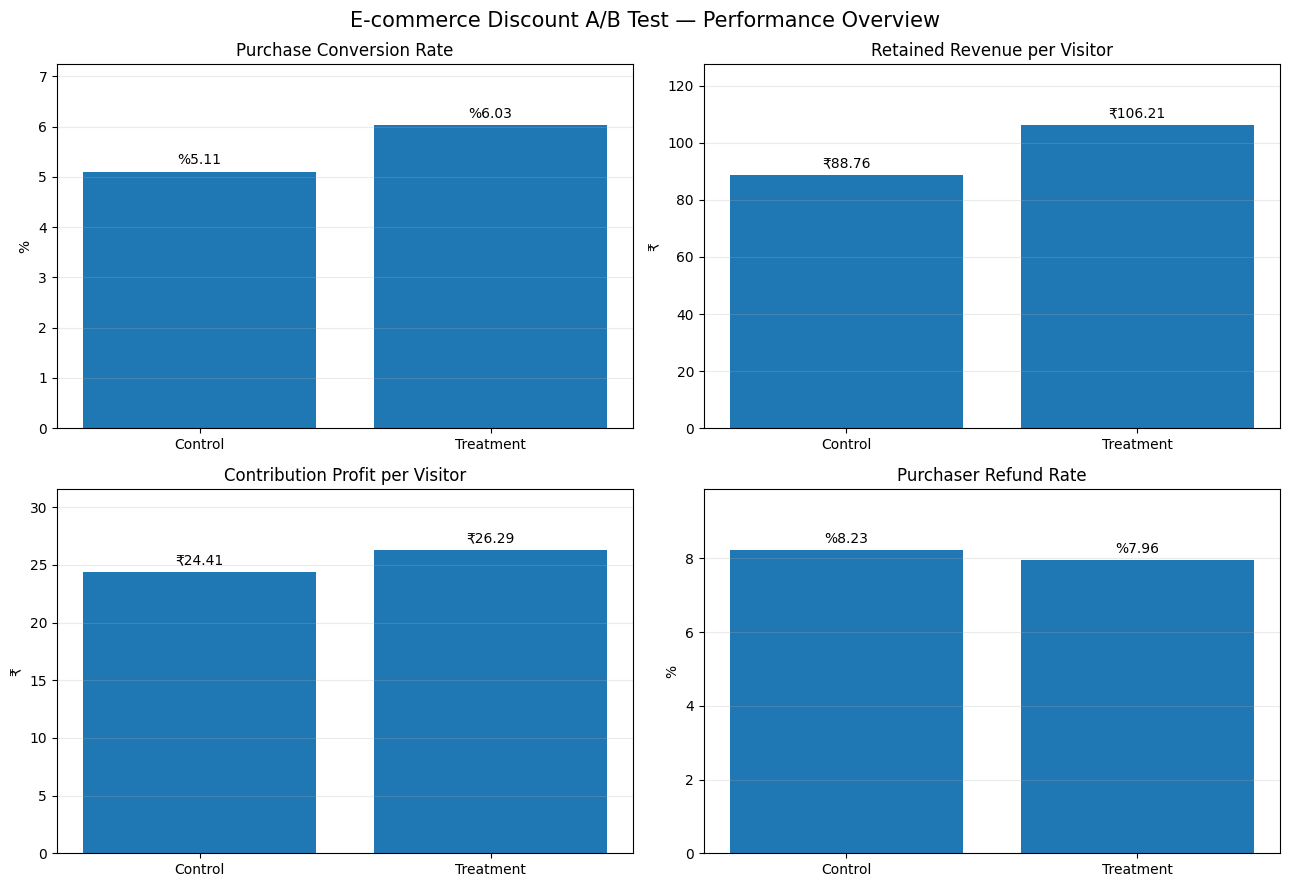

In [41]:
import matplotlib.pyplot as plt

# Prepare summary metrics
dashboard_summary = (
    experiment_df
    .groupby("variant")
    .agg(
        users=("user_id", "count"),
        purchasers=("purchase_flag", "sum"),
        refunds=("refund_flag", "sum"),
        retained_revenue=("retained_revenue", "sum"),
        contribution_profit=("contribution_profit", "sum")
    )
    .reindex(["Control", "Treatment"])
)

dashboard_summary["conversion_rate"] = (
    dashboard_summary["purchasers"]
    / dashboard_summary["users"] * 100
)

dashboard_summary["revenue_per_visitor"] = (
    dashboard_summary["retained_revenue"]
    / dashboard_summary["users"]
)

dashboard_summary["profit_per_visitor"] = (
    dashboard_summary["contribution_profit"]
    / dashboard_summary["users"]
)

dashboard_summary["refund_rate"] = (
    dashboard_summary["refunds"]
    / dashboard_summary["purchasers"] * 100
)

# Create a 2x2 visualization dashboard
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = [
    ("conversion_rate", "Purchase Conversion Rate", "%", ".2f"),
    ("revenue_per_visitor", "Retained Revenue per Visitor", "₹", ".2f"),
    ("profit_per_visitor", "Contribution Profit per Visitor", "₹", ".2f"),
    ("refund_rate", "Purchaser Refund Rate", "%", ".2f")
]

for ax, (column, title, prefix, number_format) in zip(
    axes.flatten(), metrics
):
    values = dashboard_summary[column].values
    bars = ax.bar(["Control", "Treatment"], values)

    ax.set_title(title)
    ax.set_ylabel(prefix)
    ax.bar_label(
        bars,
        labels=[
            f"{prefix}{format(value, number_format)}"
            for value in values
        ],
        padding=3
    )
    ax.set_ylim(0, max(values) * 1.20)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "E-commerce Discount A/B Test — Performance Overview",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Overall A/B Testing Dashboard — Observation

Treatment recorded higher conversion (6.03% vs. 5.11%),
higher retained revenue per visitor (₹106.21 vs. ₹88.76),
and higher contribution profit per visitor (₹26.29 vs. ₹24.41).

Treatment also recorded a slightly lower purchaser refund rate
(7.96% vs. 8.23%).

These are descriptive comparisons. Statistical conclusions
are based on the separately calculated hypothesis tests
and confidence intervals.

All results are based on synthetic data.

## Segment Performance and Confidence Interval Visualizations

We visualize:
1. Treatment-minus-Control conversion lift across customer segments.
2. Holm-adjusted statistical significance for segment comparisons.
3. Overall conversion lift with its 95% Newcombe confidence interval.
4. Contribution-profit difference with its 95% bootstrap confidence interval.

These visualizations support interpretation of the experiment results.

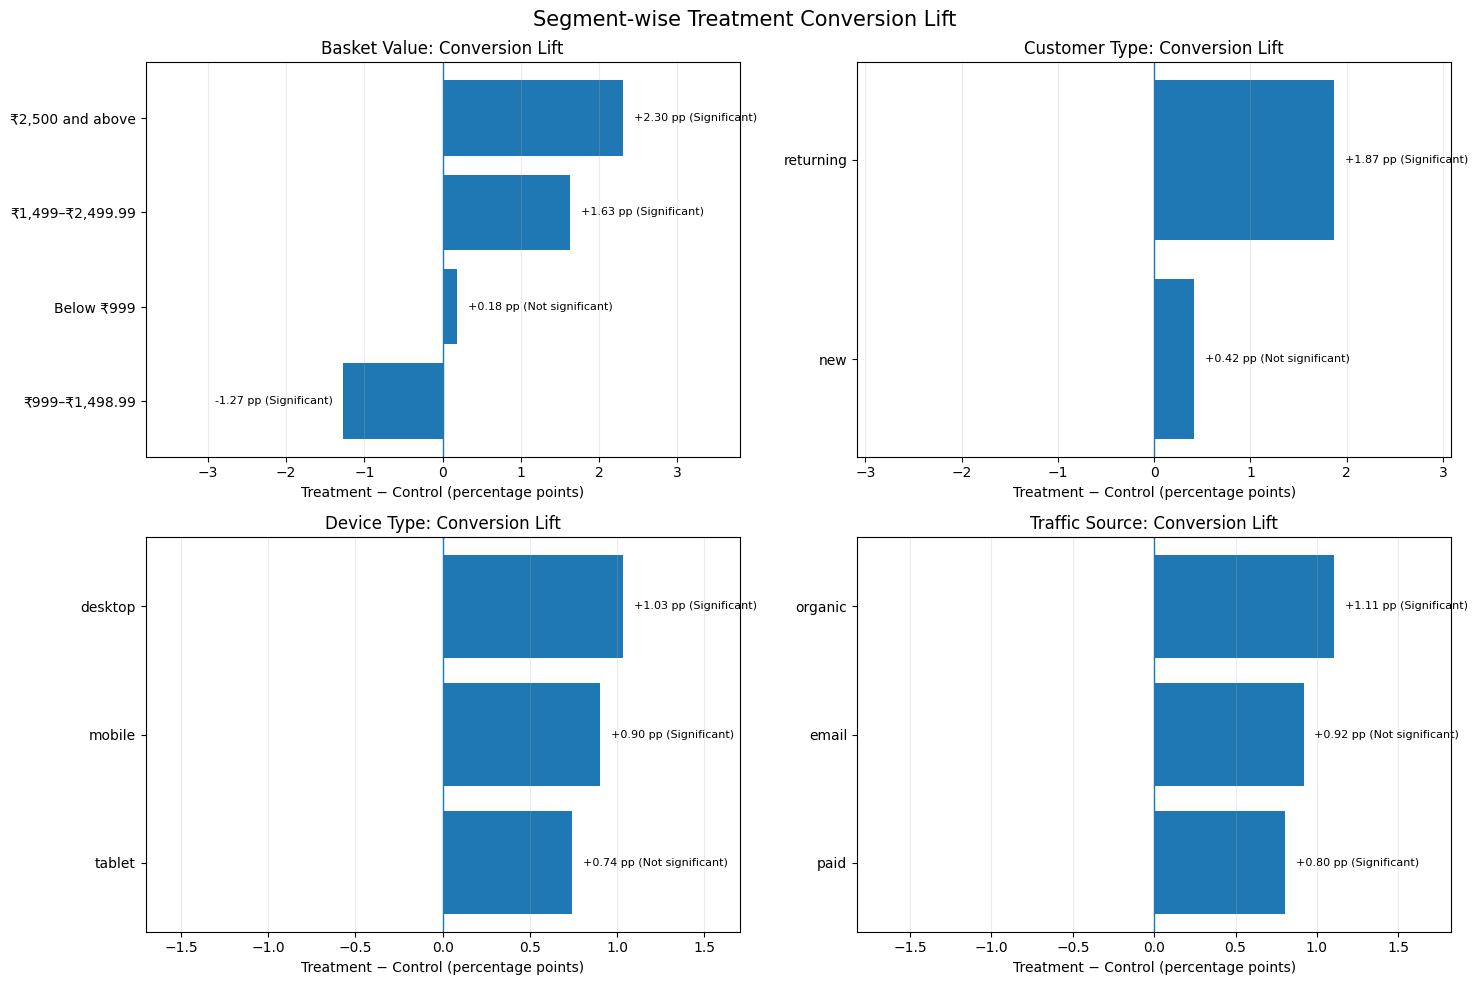

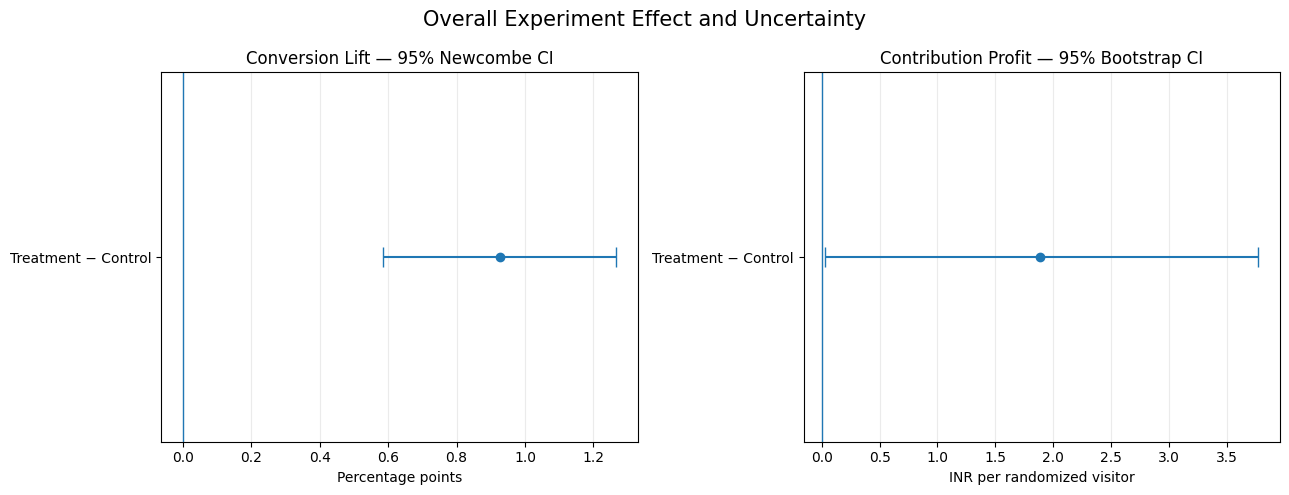

Segment and confidence interval charts generated.


In [42]:
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Chart 1: Segment-wise conversion lift
# --------------------------------------------------

dimensions = [
    "Basket Value",
    "Customer Type",
    "Device Type",
    "Traffic Source"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, dimension in zip(axes.flatten(), dimensions):

    plot_data = segment_test_results[
        segment_test_results["dimension"] == dimension
    ].copy()

    plot_data = plot_data.sort_values("lift_pp")

    bars = ax.barh(
        plot_data["segment"],
        plot_data["lift_pp"]
    )

    ax.axvline(0, linewidth=1)
    ax.set_title(f"{dimension}: Conversion Lift")
    ax.set_xlabel("Treatment − Control (percentage points)")
    ax.grid(axis="x", alpha=0.25)

    max_lift = max(abs(plot_data["lift_pp"]).max(), 0.1)
    padding = max_lift * 0.06

    for bar, (_, row) in zip(bars, plot_data.iterrows()):

        label = (
            "Significant"
            if row["significant_after_holm"]
            else "Not significant"
        )

        value = row["lift_pp"]

        ax.text(
            value + padding if value >= 0 else value - padding,
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.2f} pp ({label})",
            va="center",
            ha="left" if value >= 0 else "right",
            fontsize=8
        )

    ax.set_xlim(
        -max_lift * 1.65,
        max_lift * 1.65
    )

fig.suptitle(
    "Segment-wise Treatment Conversion Lift",
    fontsize=15
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# Chart 2: Overall effect confidence intervals
# --------------------------------------------------

profit_result = bootstrap_results[
    "Contribution profit per visitor"
]

conversion_point = absolute_lift * 100
conversion_lower = ci_lower * 100
conversion_upper = ci_upper * 100

profit_point = profit_result["difference"]
profit_lower = profit_result["lower_bound"]
profit_upper = profit_result["upper_bound"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Conversion confidence interval
axes[0].errorbar(
    conversion_point,
    0,
    xerr=[[
        conversion_point - conversion_lower
    ], [
        conversion_upper - conversion_point
    ]],
    fmt="o",
    capsize=7
)

axes[0].axvline(0, linewidth=1)
axes[0].set_yticks([0], ["Treatment − Control"])
axes[0].set_xlabel("Percentage points")
axes[0].set_title("Conversion Lift — 95% Newcombe CI")
axes[0].grid(axis="x", alpha=0.25)

# Profit confidence interval
axes[1].errorbar(
    profit_point,
    0,
    xerr=[[
        profit_point - profit_lower
    ], [
        profit_upper - profit_point
    ]],
    fmt="o",
    capsize=7
)

axes[1].axvline(0, linewidth=1)
axes[1].set_yticks([0], ["Treatment − Control"])
axes[1].set_xlabel("INR per randomized visitor")
axes[1].set_title("Contribution Profit — 95% Bootstrap CI")
axes[1].grid(axis="x", alpha=0.25)

fig.suptitle("Overall Experiment Effect and Uncertainty", fontsize=15)

plt.tight_layout()
plt.show()

print("Segment and confidence interval charts generated.")